In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
data = pd.read_csv(r'E:\Info_Srping\FWI_Prediction\Data\processed\train_data.csv')
data

FileNotFoundError: [Errno 2] No such file or directory: 'E:\\Info_Srping\\FWI_Prediction\\Data\\processed\\train_data.csv'

In [ ]:
data.drop(['report_date'], axis =1 , inplace = True)

In [11]:
data.columns

Index(['temperature', 'dew_point_temperature', 'relative_humidity',
       'wind_speed', 'wind_direction', 'atmospheric_pressure', 'visibility',
       'precipitation', 'rain_days', 'snow_on_ground',
       'fine_fuel_moisture_code', 'duff_moisture_code', 'drought_code',
       'build_up_index', 'initial_spread_index', 'fire_weather_index',
       'daily_severity_rating', 'country', 'latitude', 'longitude',
       'elevation'],
      dtype='object')

In [4]:
data

,temperature,dew_point_temperature,relative_humidity,wind_speed,wind_direction,atmospheric_pressure,visibility,precipitation,rain_days,snow_on_ground,...,duff_moisture_code,drought_code,build_up_index,initial_spread_index,fire_weather_index,daily_severity_rating,country,latitude,longitude,elevation
0,12.0,7.6,74.4,12.0,0,1015.13,30.0,2.6,0,0.0,...,6.9,51.1,10.3,0.9,0.6,0.0,United Kingdom,54.502224,-2.68500,252.0
1,11.1,1.7,52.0,22.1,200,1010.80,38.6,1.5,0,0.0,...,14.8,104.2,21.9,1.7,2.7,0.2,Canada,55.200000,-119.40000,745.0
2,2.9,2.3,95.0,1.9,250,1018.19,27.7,0.0,2,0.0,...,3.1,330.1,6.1,0.1,0.0,0.0,Canada,49.820000,-74.98000,381.1
3,22.1,11.1,49.8,9.5,267,1015.79,23.9,0.0,4,0.0,...,11.4,282.9,20.7,3.8,6.3,0.7,Canada,54.280000,-111.45000,619.0
4,17.0,10.0,63.6,35.2,260,1016.70,16.1,0.0,1,0.0,...,107.4,482.9,138.1,15.6,47.7,25.4,United States,37.618805,-122.37542,4.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1183935,22.5,15.4,63.0,35.2,180,1016.90,10.1,0.0,2,0.0,...,11.5,27.6,11.5,16.9,16.3,3.8,Canada,45.230000,-63.06000,23.5
1183936,17.4,12.1,70.0,22.2,300,1018.30,49.7,0.0,10,0.0,...,20.6,334.2,35.6,6.1,12.8,2.5,Canada,49.350000,-124.16000,14.5
1183937,21.0,15.0,68.7,13.0,200,1014.50,14.5,0.0,1,0.0,...,5.2,107.5,9.3,2.1,1.8,0.1,Canada,43.628613,-79.39500,76.8
1183938,16.2,-1.4,31.0,25.9,220,1016.50,48.3,0.0,3,0.0,...,12.1,21.5,12.0,15.3,15.4,3.4,Canada,45.466667,-73.75000,36.0


In [5]:
data['country'].value_counts()

country
Canada            807605
United States     281247
United Kingdom     53620
France             32996
Spain               8472
Name: count, dtype: int64

In [6]:
data.describe()

,temperature,dew_point_temperature,relative_humidity,wind_speed,wind_direction,atmospheric_pressure,visibility,precipitation,rain_days,snow_on_ground,fine_fuel_moisture_code,duff_moisture_code,drought_code,build_up_index,initial_spread_index,fire_weather_index,daily_severity_rating,latitude,longitude,elevation
count,1.183940e+06,1.183940e+06,1.183940e+06,1.183940e+06,1.183940e+06,1.183940e+06,1.183940e+06,1.183940e+06,1.183940e+06,1.183940e+06,1.183940e+06,1.183940e+06,1.183940e+06,1.183940e+06,1.183940e+06,1.183940e+06,1.183940e+06,1.183940e+06,1.183940e+06,1.183940e+06
mean,1.668612e+01,7.259459e+00,5.820395e+01,1.504548e+01,1.949920e+02,1.014548e+03,2.232566e+01,2.515107e+00,2.503915e+00,2.043347e-04,7.359585e+01,2.795242e+01,2.481264e+02,3.985547e+01,5.402472e+00,1.113123e+01,4.292205e+00,4.809256e+01,-9.029828e+01,4.017116e+02
std,7.882160e+00,7.347719e+00,2.123150e+01,9.471568e+00,1.026935e+02,7.408052e+00,1.010250e+01,7.280202e+00,4.616901e+00,1.626673e-01,2.071138e+01,4.315803e+01,2.255217e+02,5.259738e+01,1.030672e+01,1.586873e+01,1.373021e+01,7.479609e+00,3.380908e+01,4.225162e+02
min,-7.280000e+01,-7.280000e+01,2.000000e+00,0.000000e+00,0.000000e+00,9.500000e+02,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,-9.900000e+01,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,2.590614e+01,-1.766425e+02,0.000000e+00
25%,1.120000e+01,2.500000e+00,4.230000e+01,8.000000e+00,1.200000e+02,1.010100e+03,1.610000e+01,0.000000e+00,0.000000e+00,0.000000e+00,6.460000e+01,6.400000e+00,8.070000e+01,1.000000e+01,1.000000e+00,6.000000e-01,0.000000e+00,4.426667e+01,-1.135900e+02,5.800000e+01
50%,1.700000e+01,7.700000e+00,5.750000e+01,1.300000e+01,2.100000e+02,1.014800e+03,1.990000e+01,0.000000e+00,1.000000e+00,0.000000e+00,8.240000e+01,1.550000e+01,1.982000e+02,2.410000e+01,3.100000e+00,5.500000e+00,6.000000e-01,4.913000e+01,-9.786000e+01,2.510000e+02
75%,2.220000e+01,1.230000e+01,7.420000e+01,2.040000e+01,2.800000e+02,1.019300e+03,2.500000e+01,1.500000e+00,3.000000e+00,0.000000e+00,8.800000e+01,3.340000e+01,3.490000e+02,4.990000e+01,6.800000e+00,1.530000e+01,3.400000e+00,5.273000e+01,-7.375000e+01,6.570000e+02
max,4.390000e+01,3.700000e+01,1.020000e+02,1.963000e+02,3.600000e+02,1.064300e+03,9.650000e+01,1.378600e+03,1.560000e+02,1.750000e+02,1.000000e+02,1.209300e+03,2.153300e+03,1.193500e+03,3.919700e+03,6.786000e+02,2.796300e+03,8.250000e+01,9.541389e+00,2.575000e+03


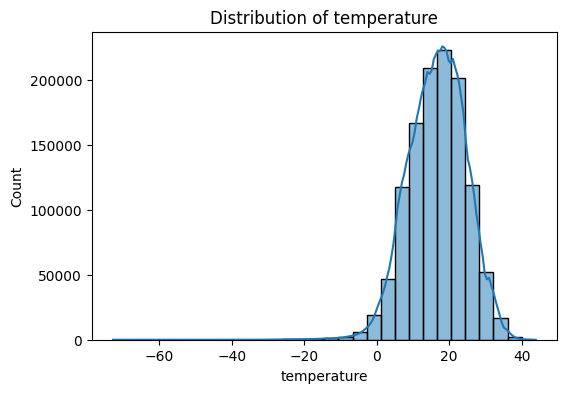

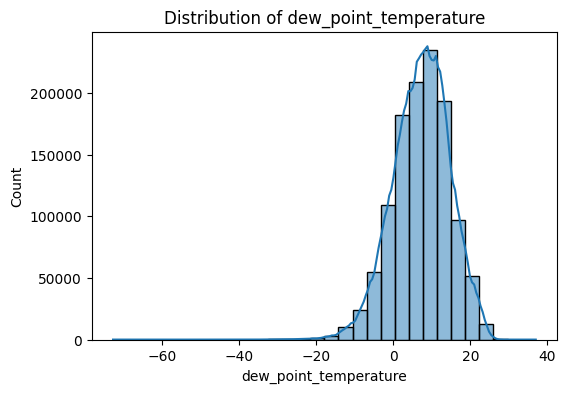

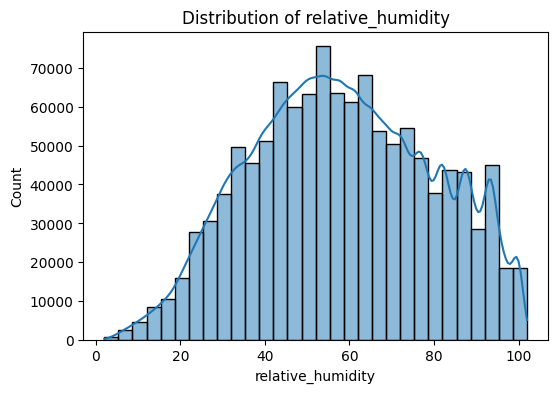

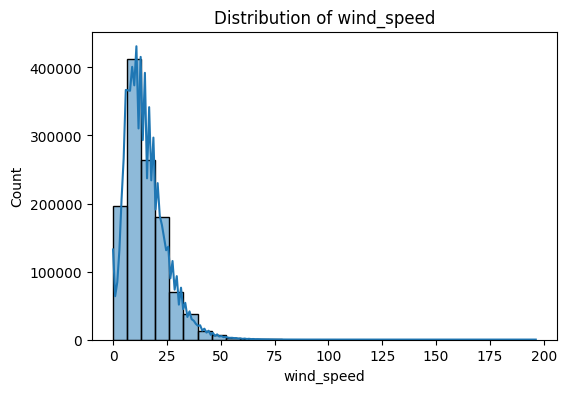

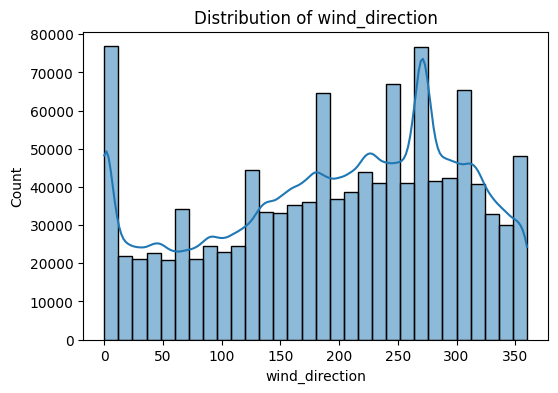

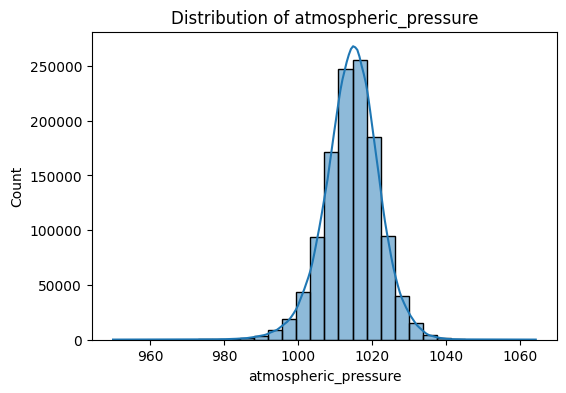

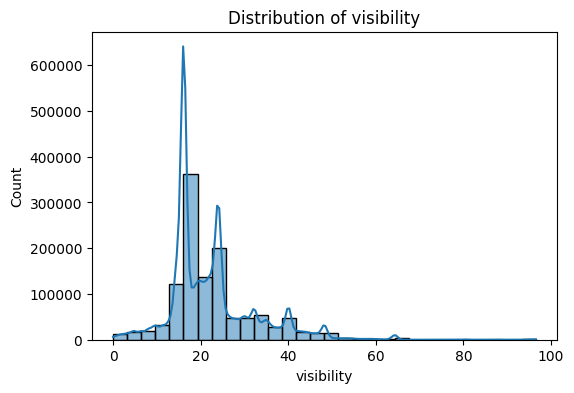

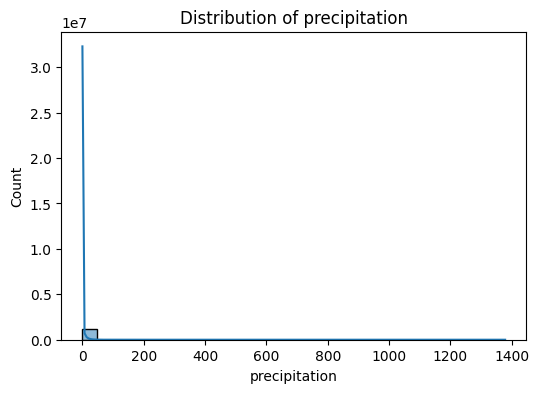

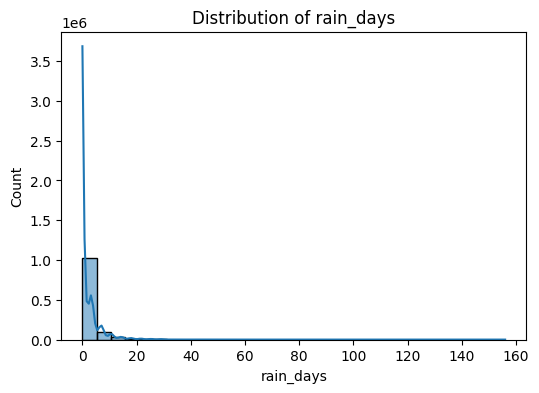

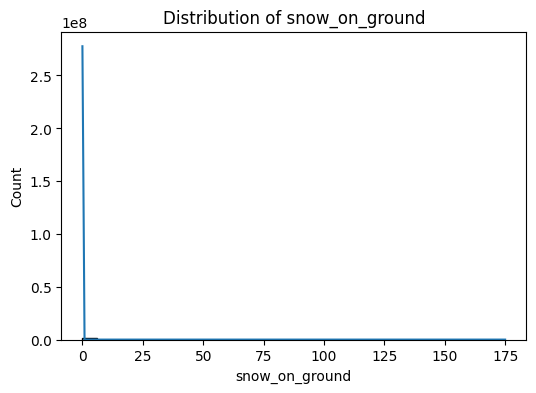

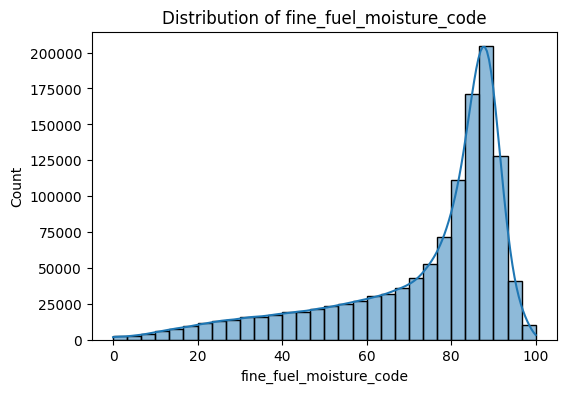

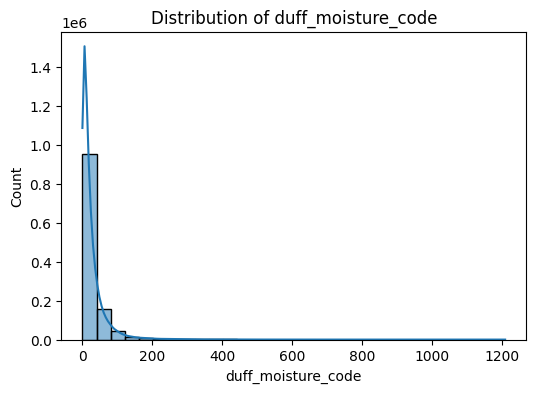

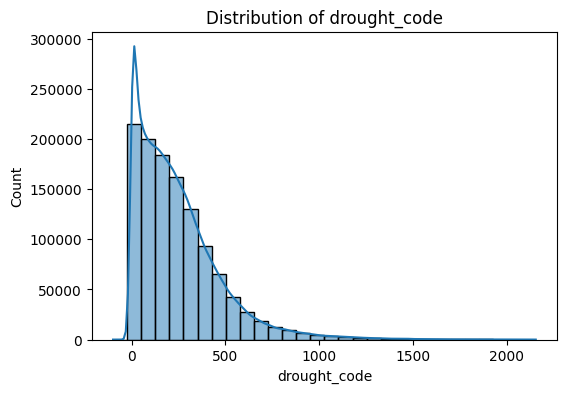

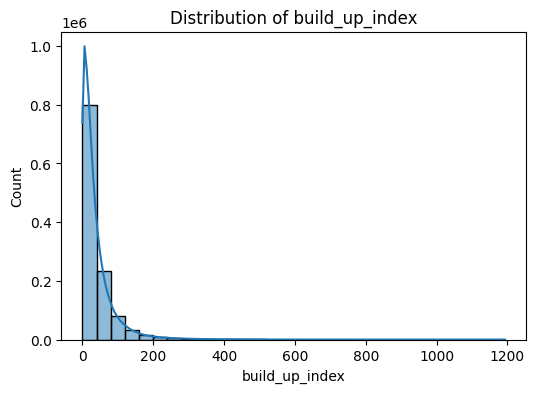

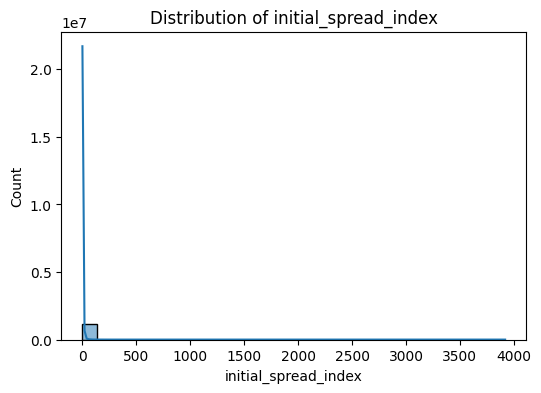

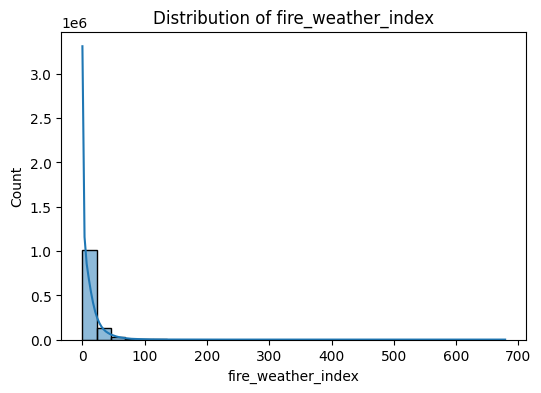

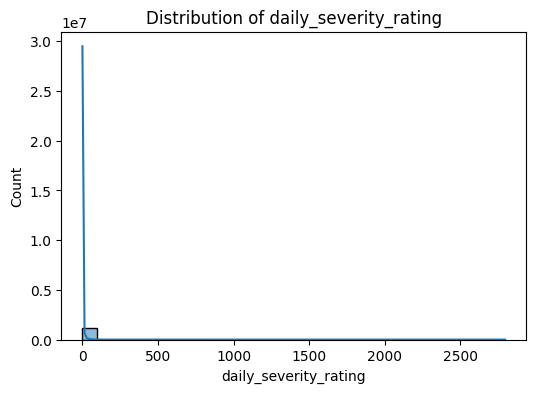

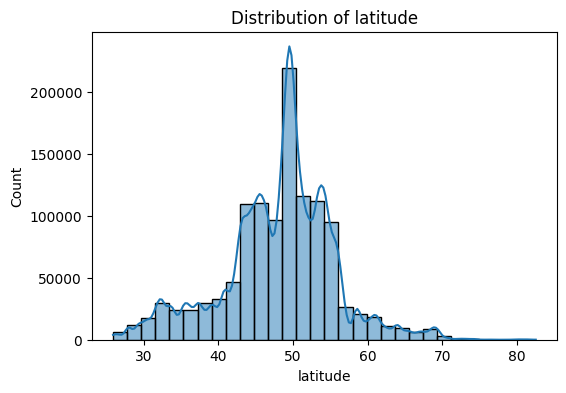

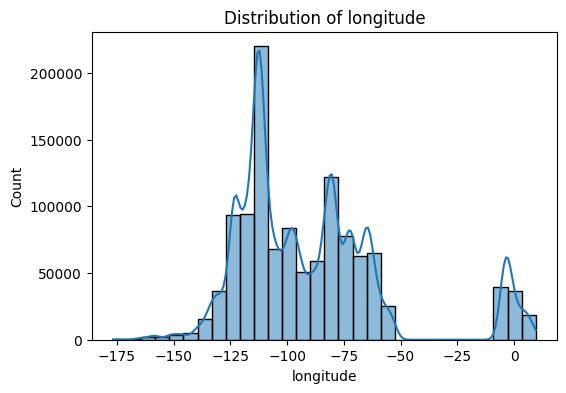

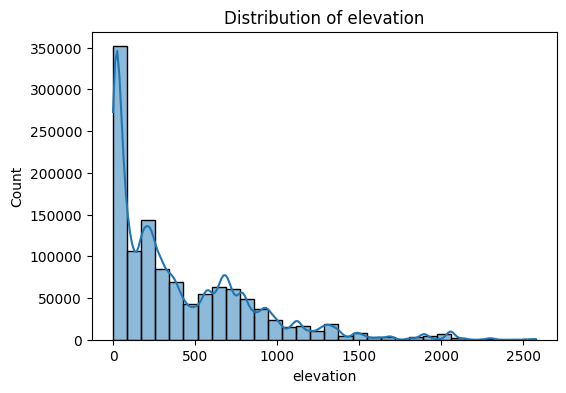

In [7]:
#Univariate Analysis

for col in data.select_dtypes(include=['float64','int64']).columns:
    plt.figure(figsize=(6,4))
    sns.histplot(data[col], kde=True, bins=30)
    plt.title(f'Distribution of {col}')
    plt.show()


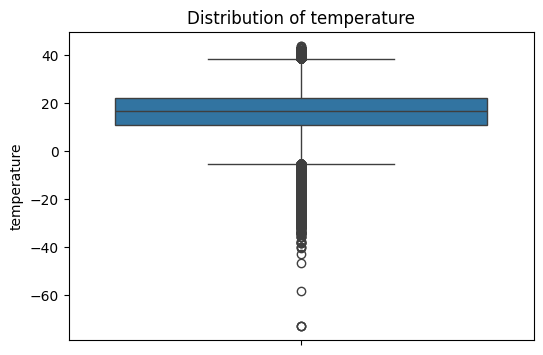

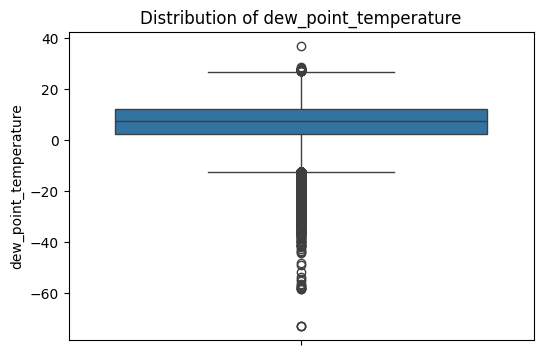

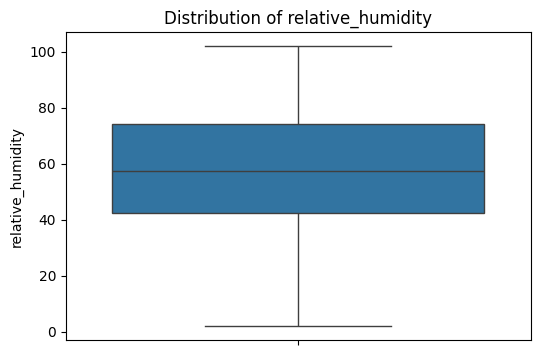

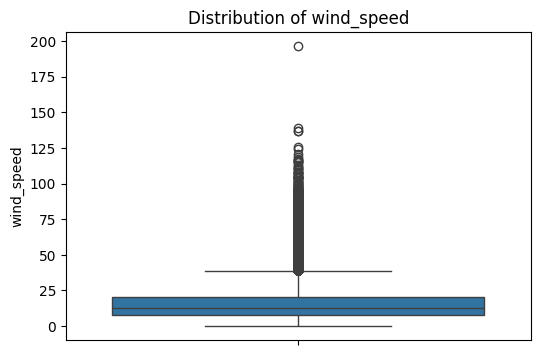

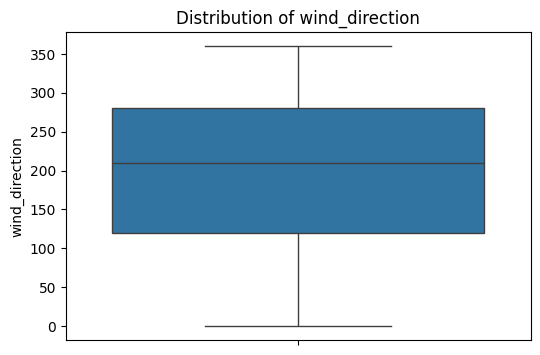

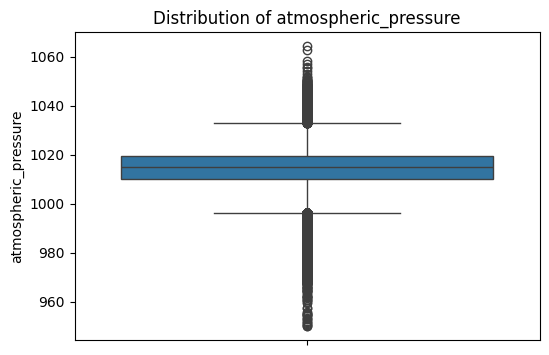

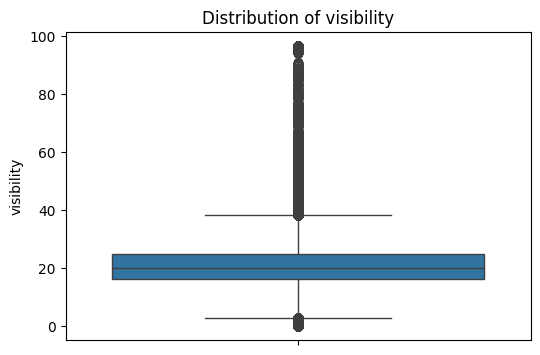

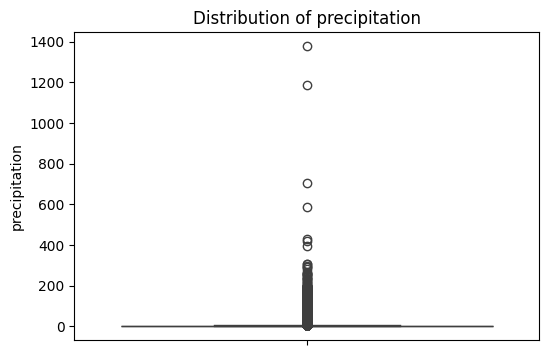

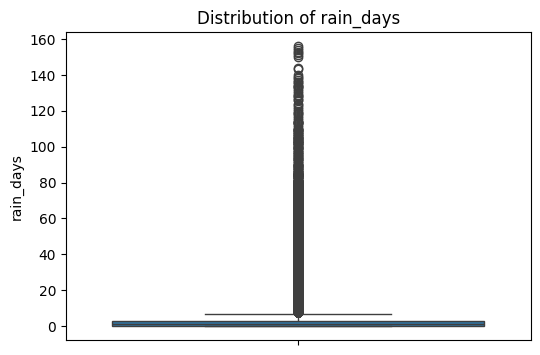

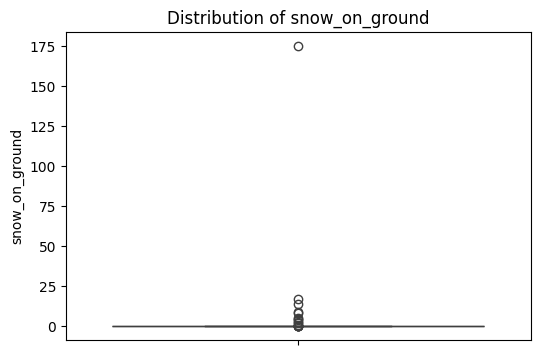

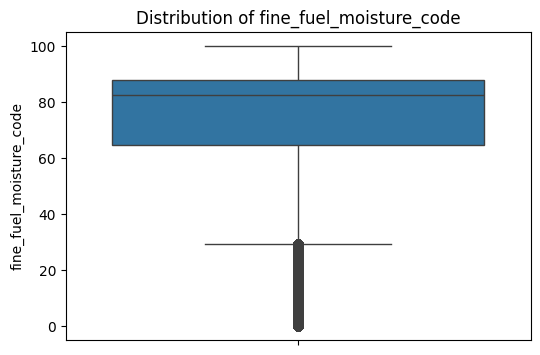

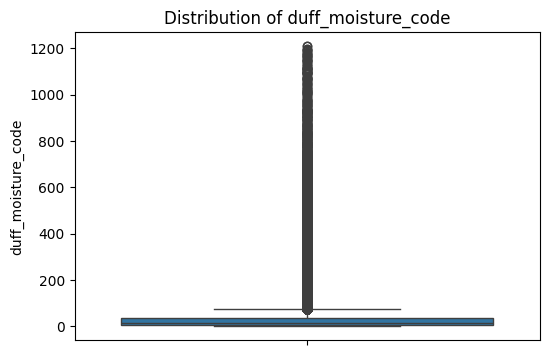

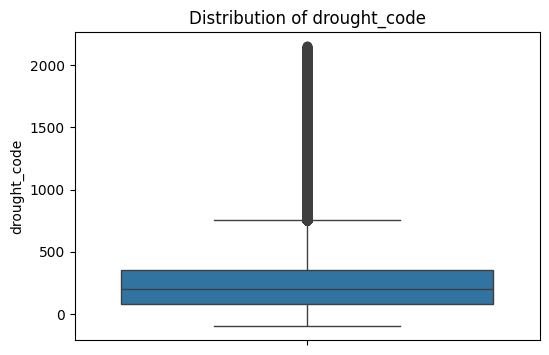

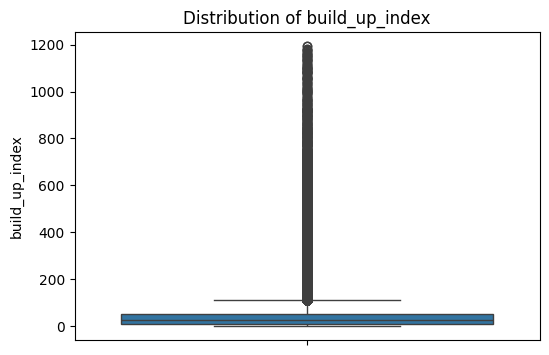

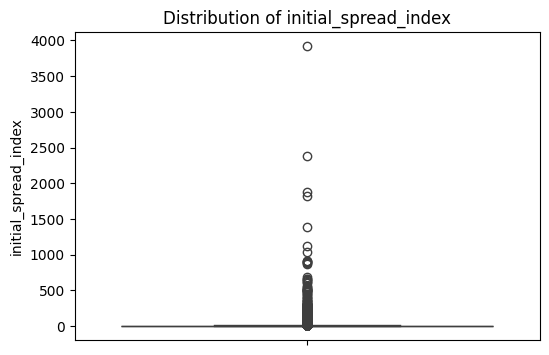

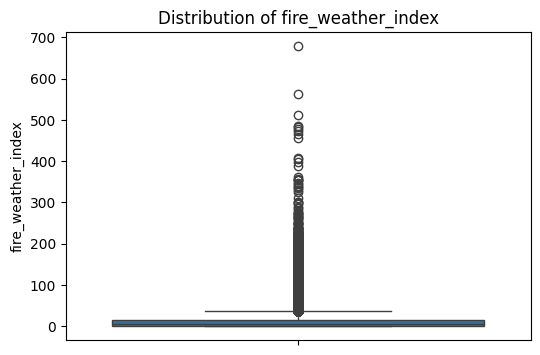

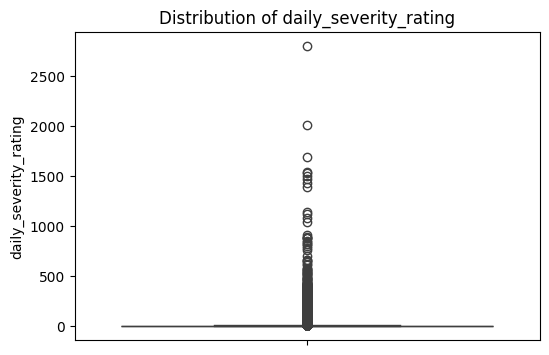

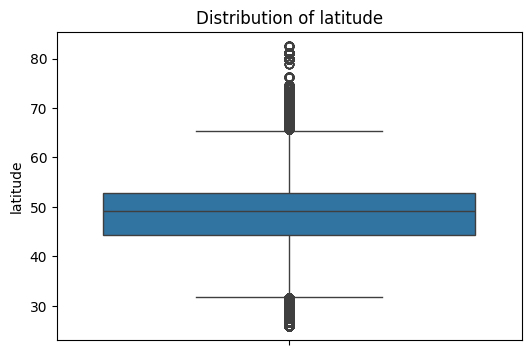

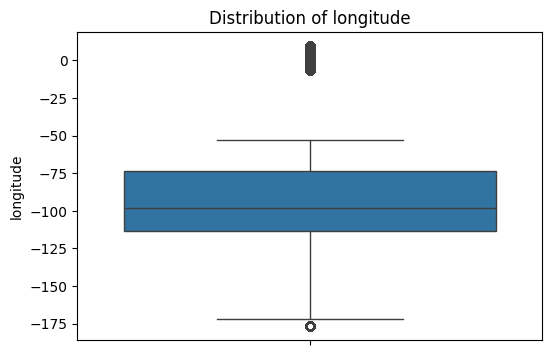

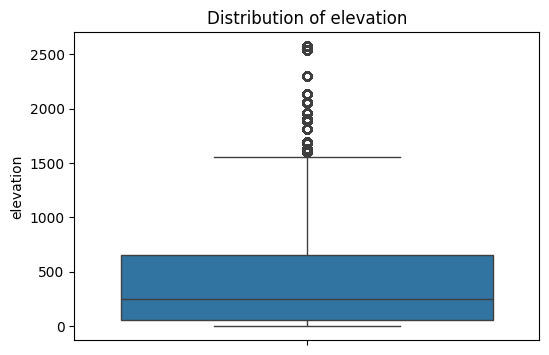

In [10]:
#Univariate Analysis

for col in data.select_dtypes(include=['float64','int64']).columns:
    plt.figure(figsize=(6,4))
    sns.boxplot(y = data[col])
    plt.title(f'Distribution of {col}')
    plt.show()


Correlations with target variable:
 fire_weather_index         1.000000
daily_severity_rating      0.850684
initial_spread_index       0.772619
build_up_index             0.700306
duff_moisture_code         0.660967
drought_code               0.565105
fine_fuel_moisture_code    0.530371
rain_days                  0.442187
temperature                0.430199
elevation                  0.409024
wind_speed                 0.288815
wind_direction             0.048333
visibility                 0.011964
snow_on_ground            -0.000368
atmospheric_pressure      -0.072115
dew_point_temperature     -0.173096
latitude                  -0.186152
longitude                 -0.199571
precipitation             -0.221897
relative_humidity         -0.617819
Name: fire_weather_index, dtype: float64


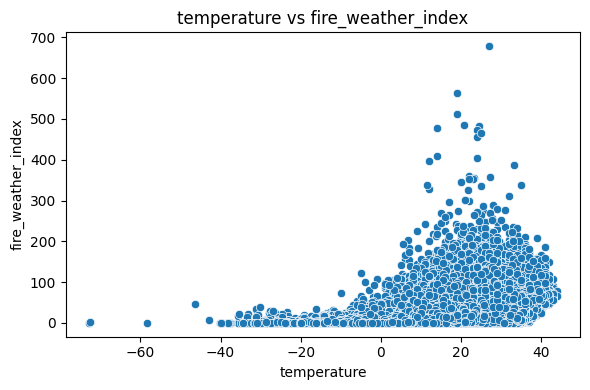

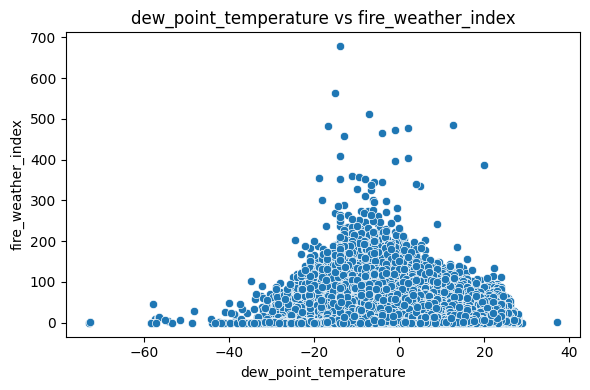

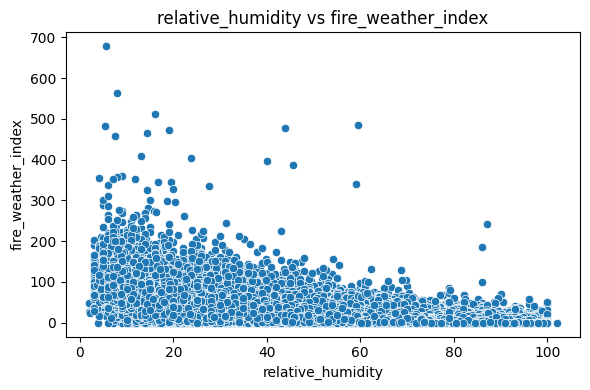

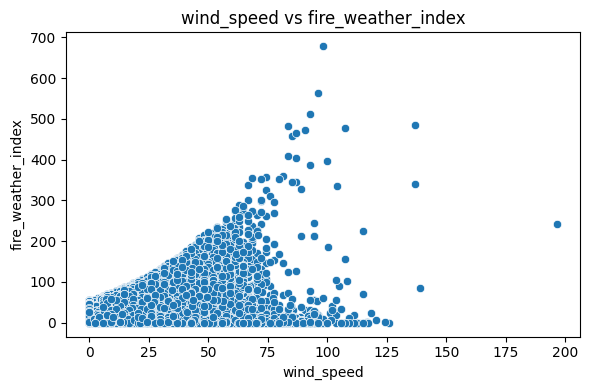

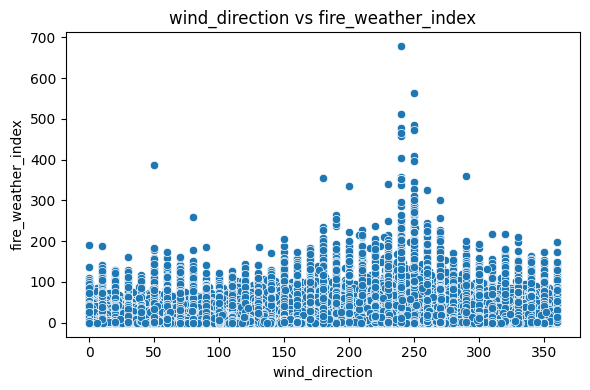

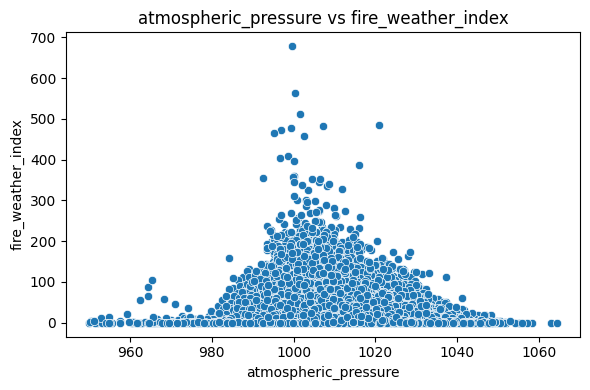

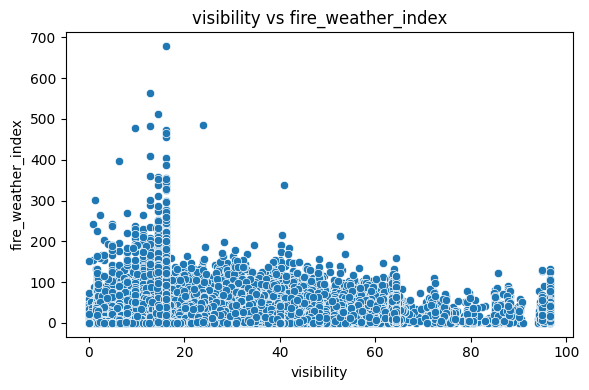

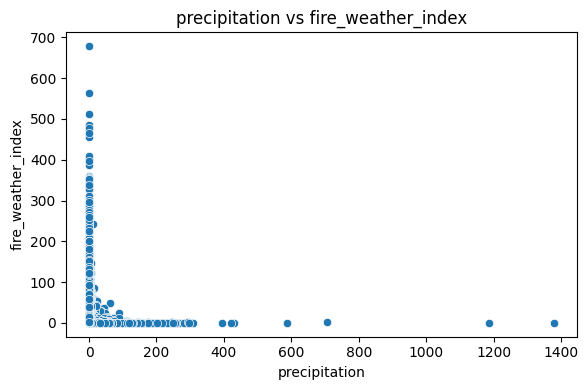

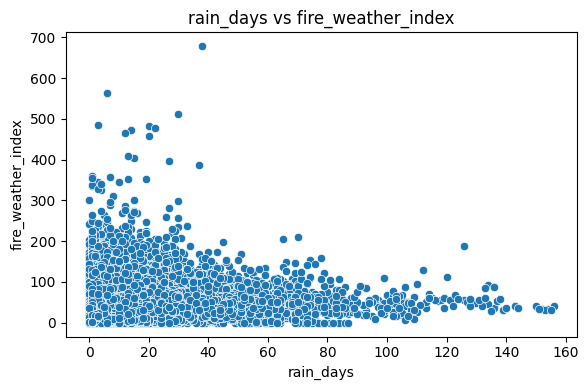

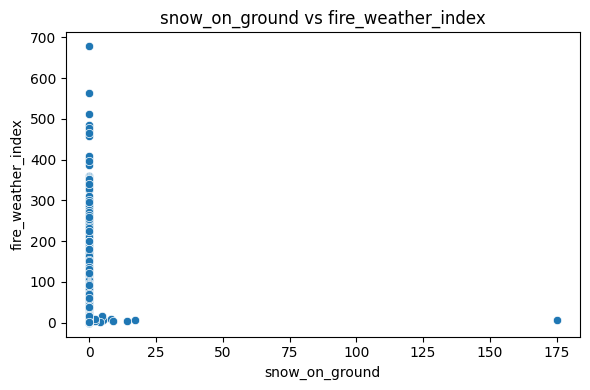

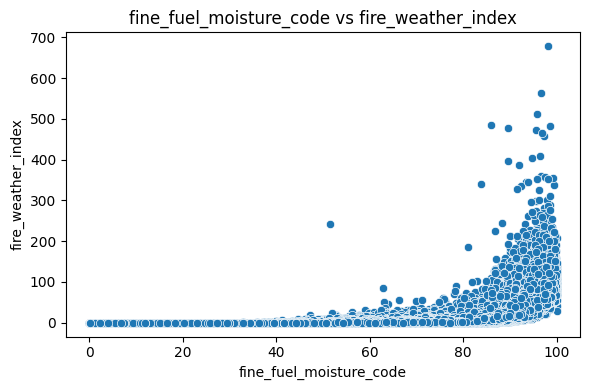

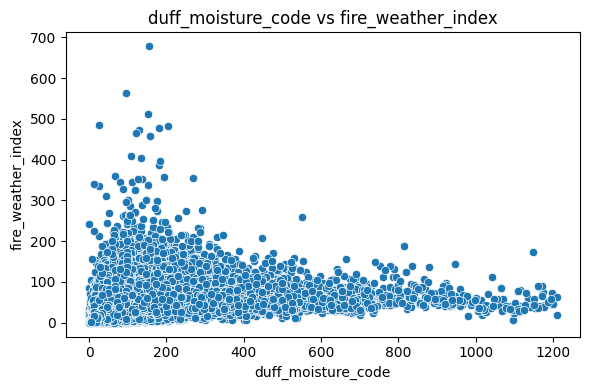

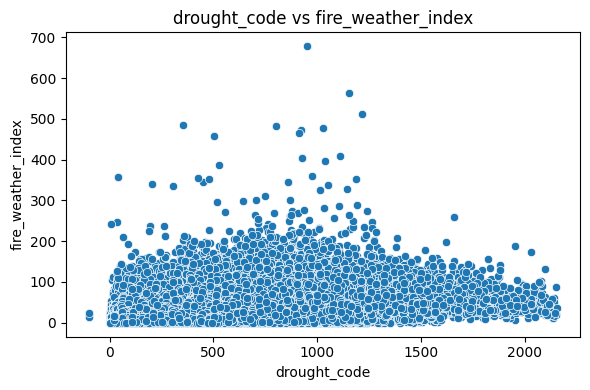

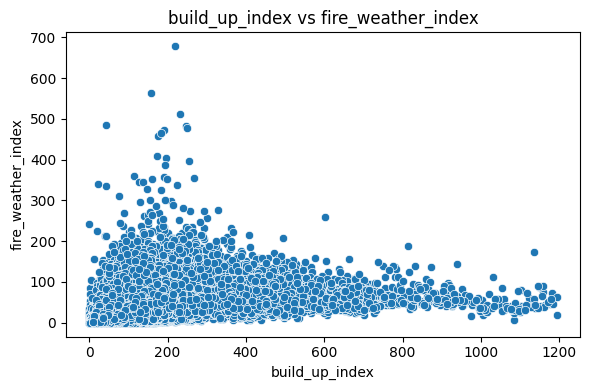

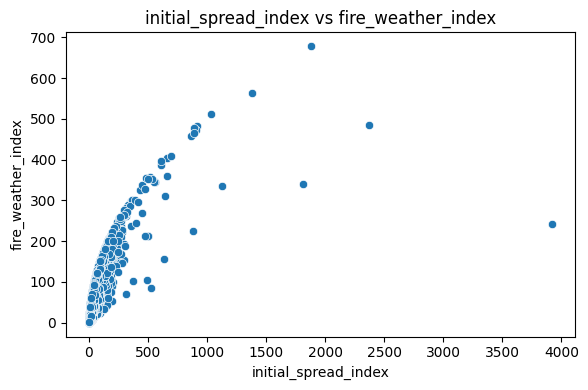

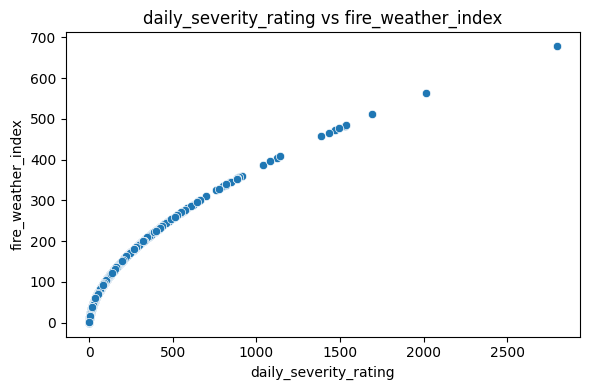

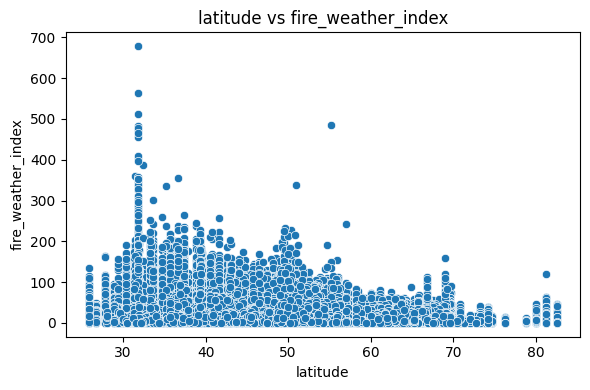

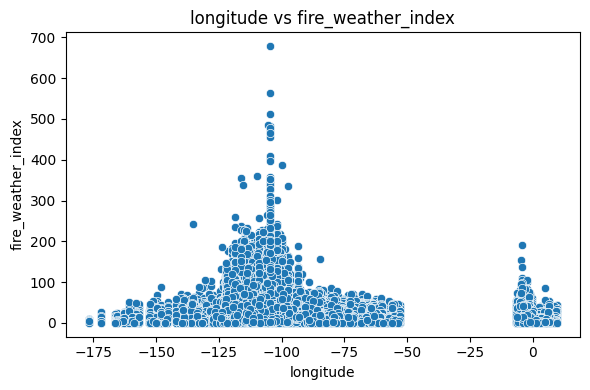

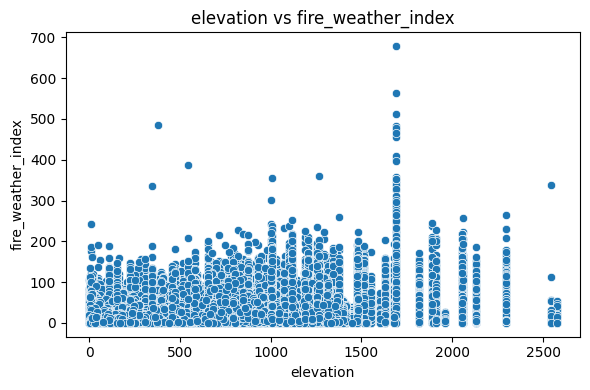

In [14]:
target = 'fire_weather_index'

numeric_data = data.select_dtypes(include=['number'])
correlations = numeric_data.corr()[target].sort_values(ascending=False)
print("Correlations with target variable:\n", correlations)

# Scatter plots for each feature vs. target variable
features = [col for col in data.columns if col != target and data[col].dtype != 'object']

for feature in features:
    plt.figure(figsize=(6, 4))
    sns.scatterplot(x=data[feature], y=data[target])
    plt.title(f'{feature} vs {target}')
    plt.xlabel(feature)
    plt.ylabel(target)
    plt.tight_layout()
    plt.show()


In [15]:
df_sample = data.sample(n=4000, random_state=42)  
print(df_sample.shape)

(4000, 21)


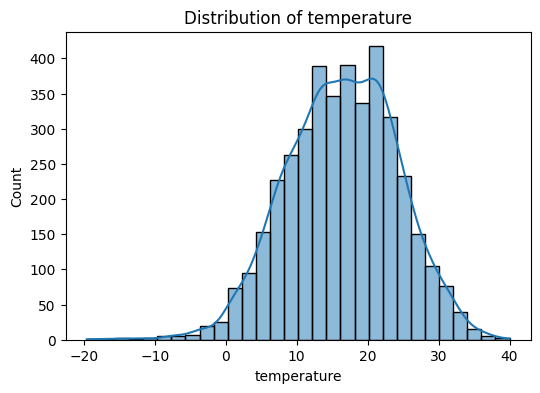

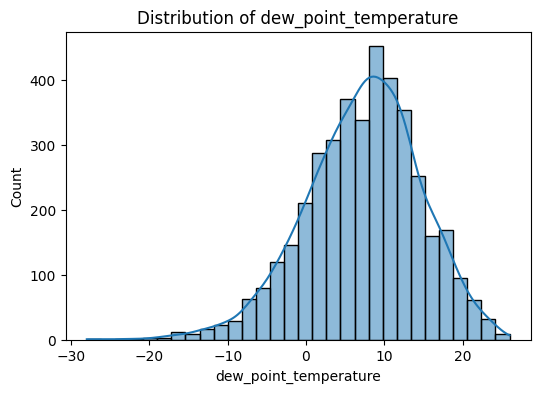

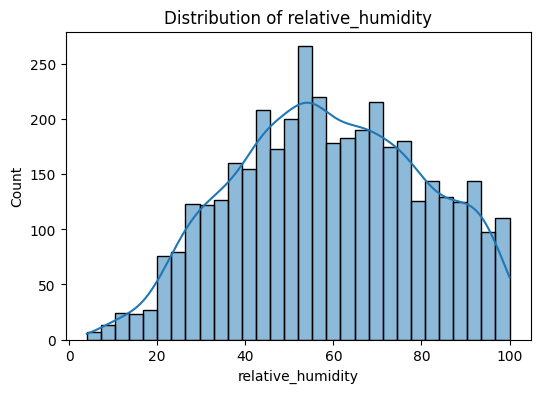

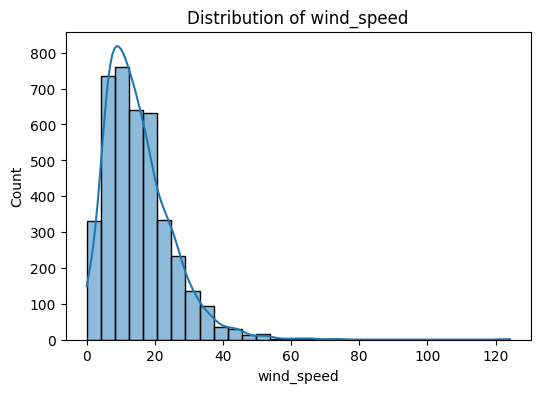

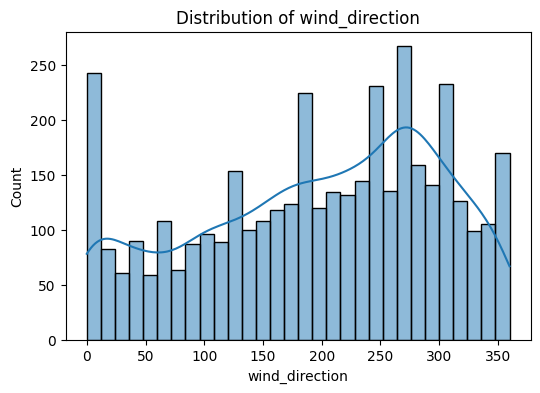

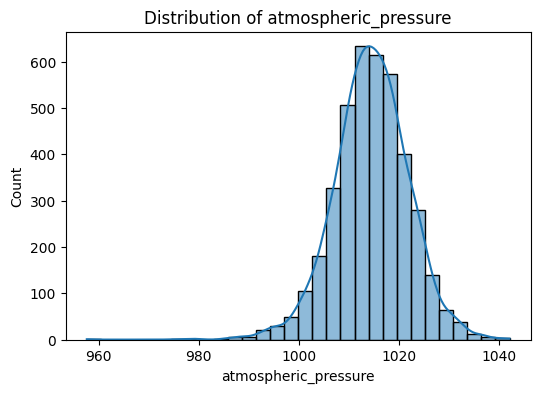

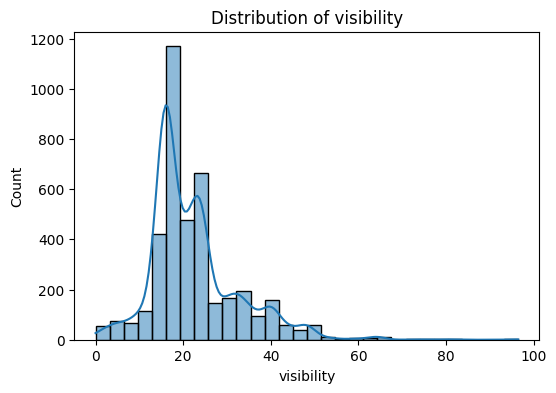

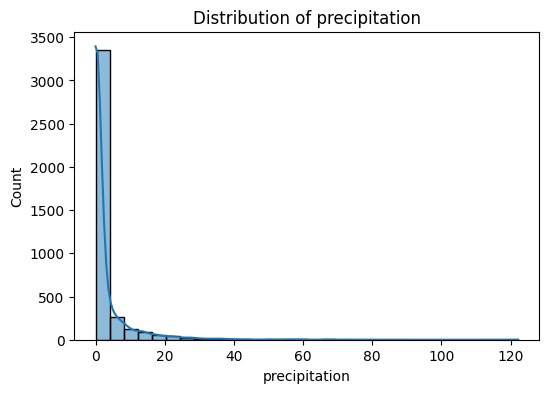

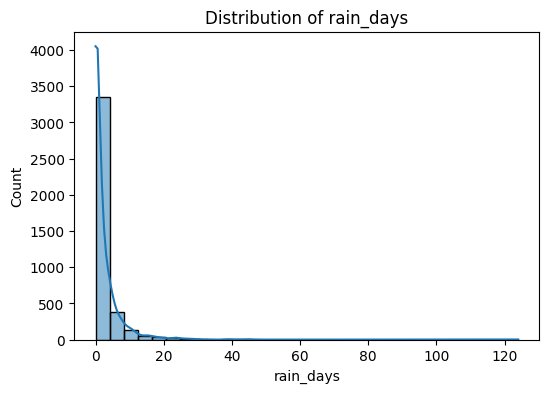

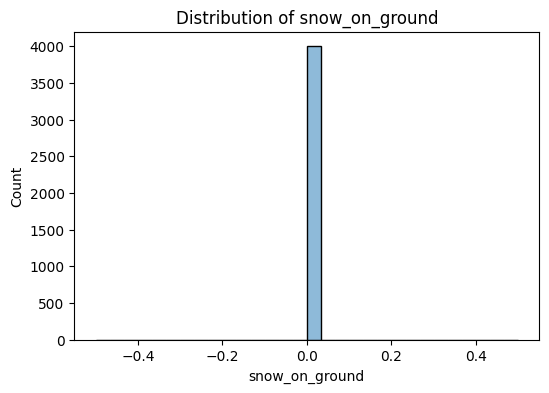

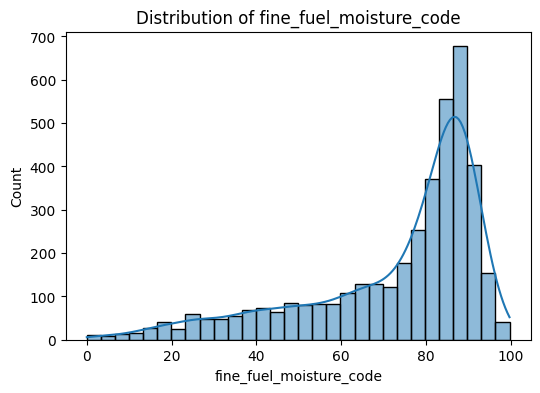

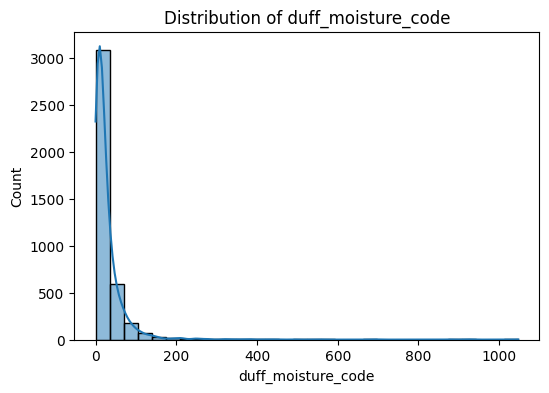

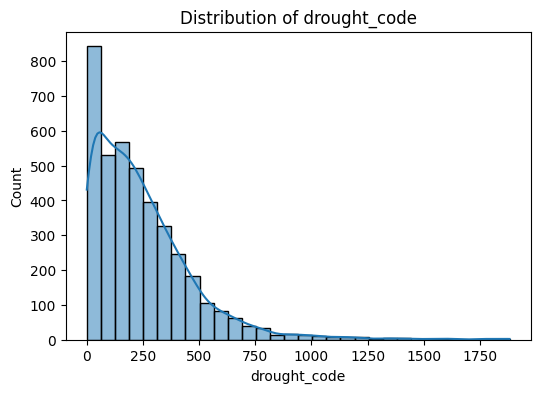

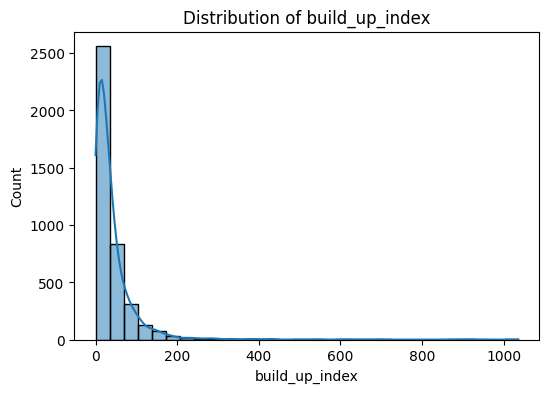

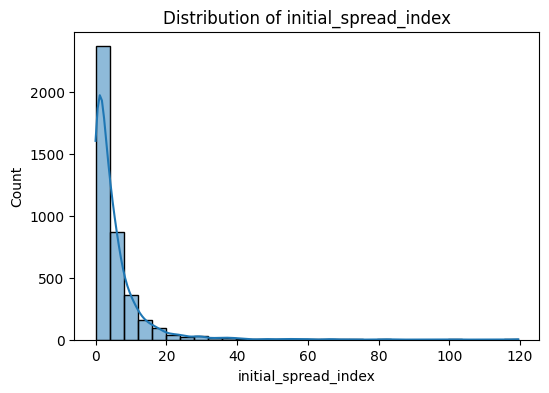

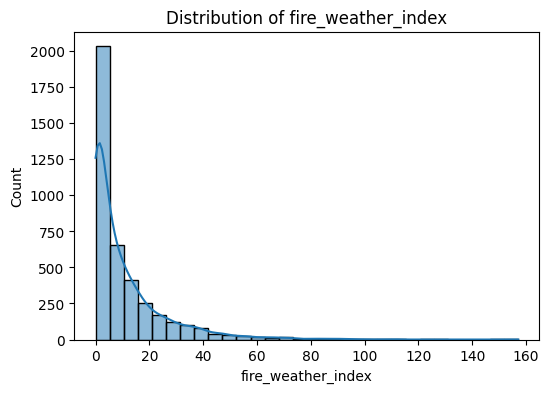

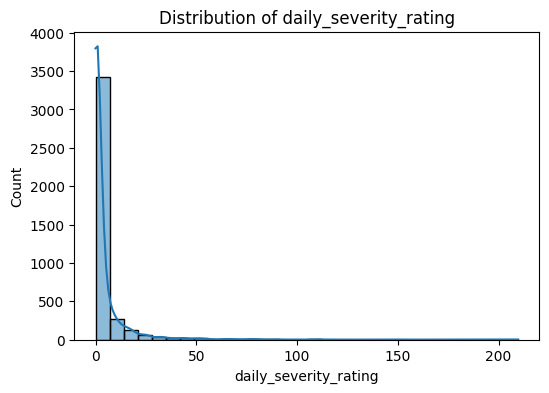

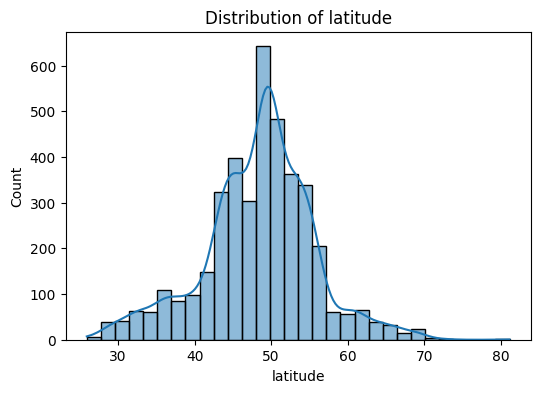

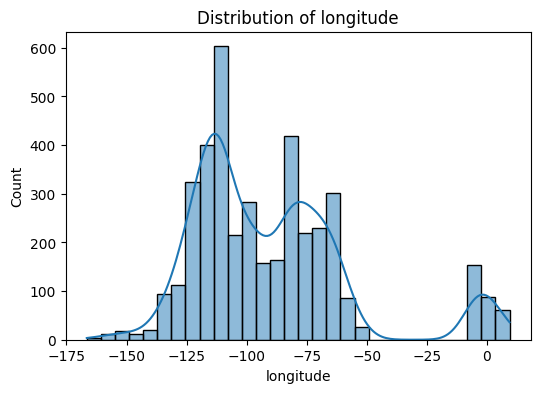

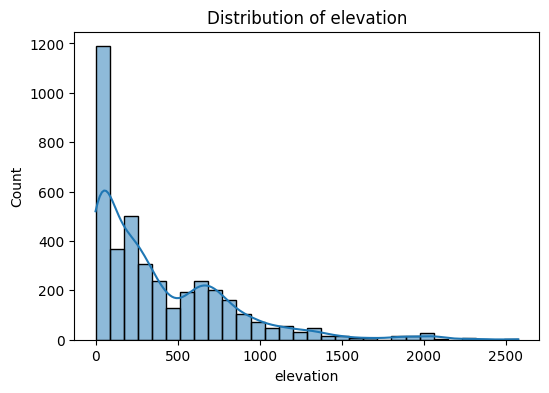

In [16]:
#Univariate Analysis

for col in df_sample.select_dtypes(include=['float64','int64']).columns:
    plt.figure(figsize=(6,4))
    sns.histplot(df_sample[col], kde=True, bins=30)
    plt.title(f'Distribution of {col}')
    plt.show()


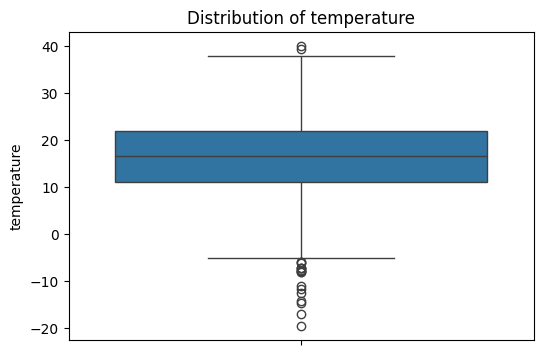

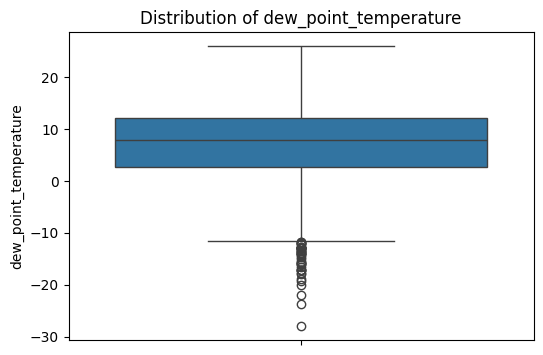

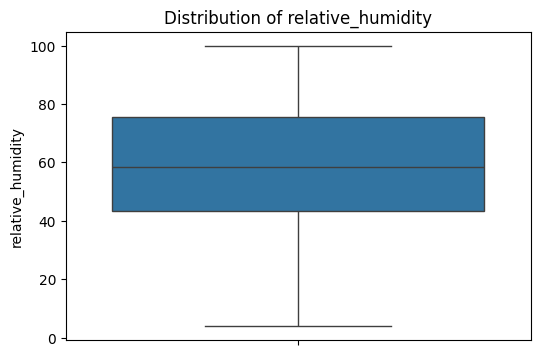

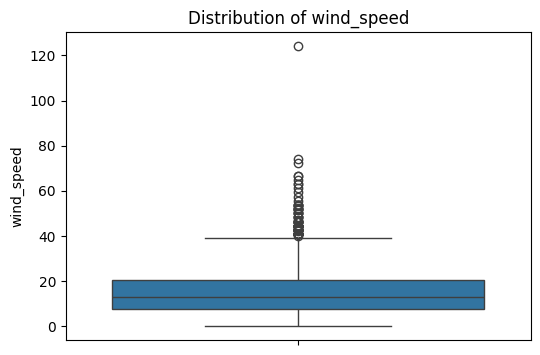

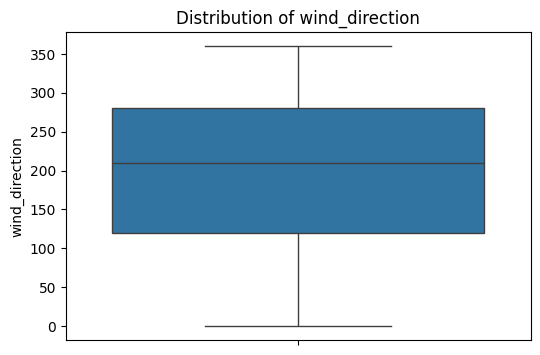

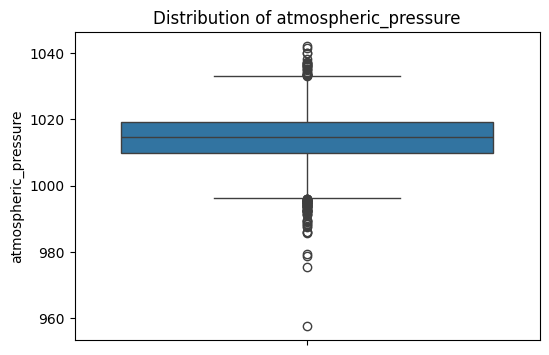

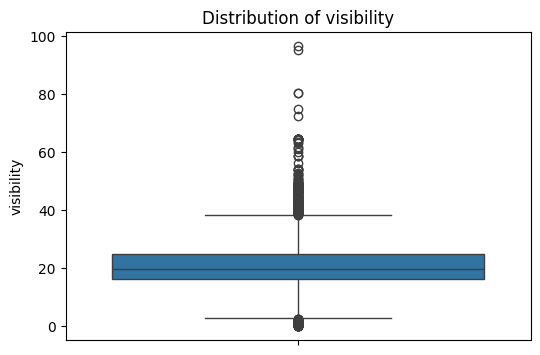

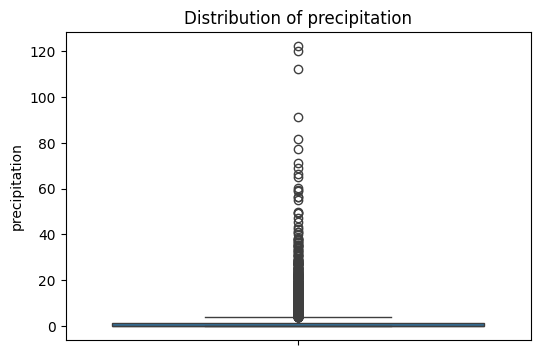

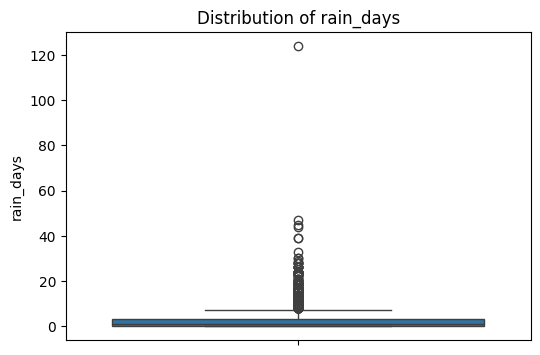

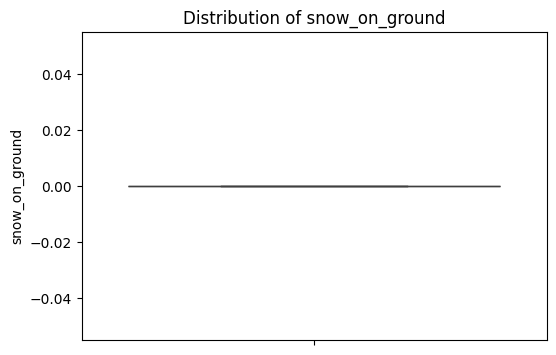

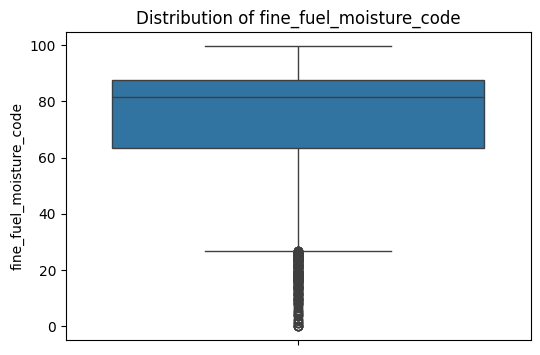

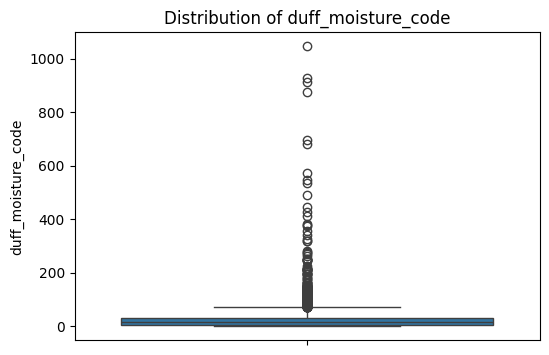

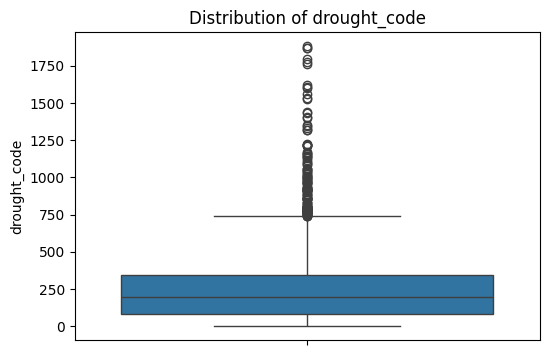

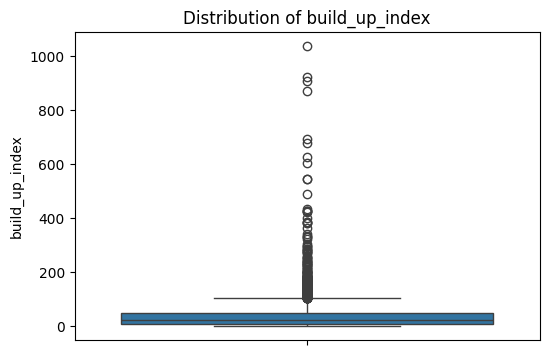

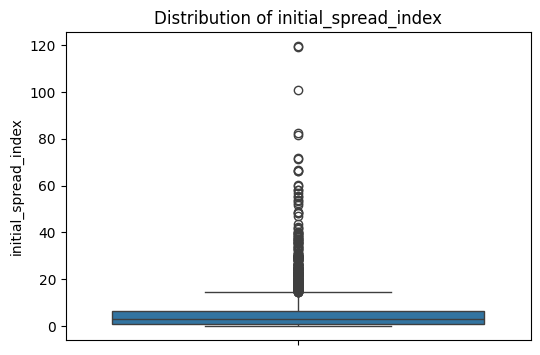

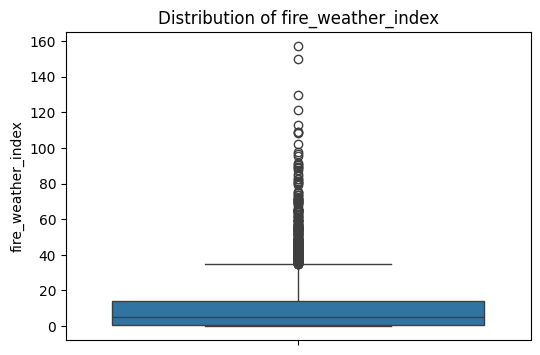

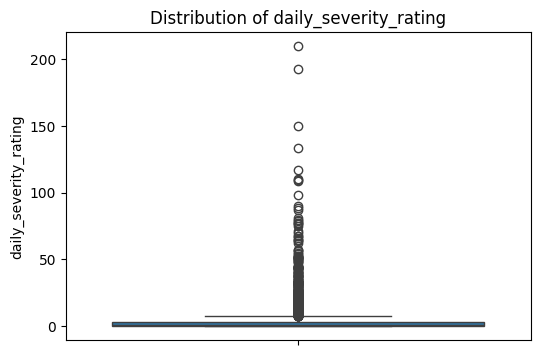

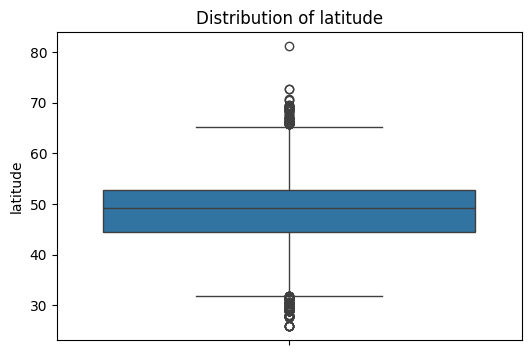

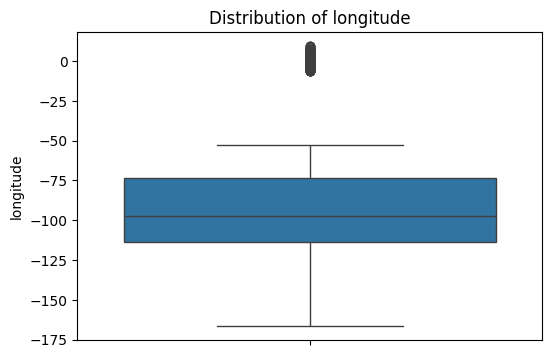

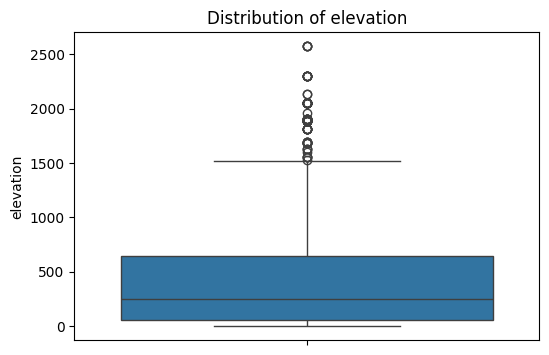

In [17]:
#Univariate Analysis

for col in df_sample.select_dtypes(include=['float64','int64']).columns:
    plt.figure(figsize=(6,4))
    sns.boxplot(y = df_sample[col])
    plt.title(f'Distribution of {col}')
    plt.show()


Correlations with target variable:
 fire_weather_index         1.000000
daily_severity_rating      0.909886
initial_spread_index       0.892885
build_up_index             0.652184
duff_moisture_code         0.589460
drought_code               0.569352
fine_fuel_moisture_code    0.539630
temperature                0.435907
rain_days                  0.423825
elevation                  0.414850
wind_speed                 0.269946
wind_direction             0.051133
visibility                 0.037566
atmospheric_pressure      -0.078380
latitude                  -0.174072
dew_point_temperature     -0.192698
longitude                 -0.193402
precipitation             -0.227914
relative_humidity         -0.637423
snow_on_ground                  NaN
Name: fire_weather_index, dtype: float64


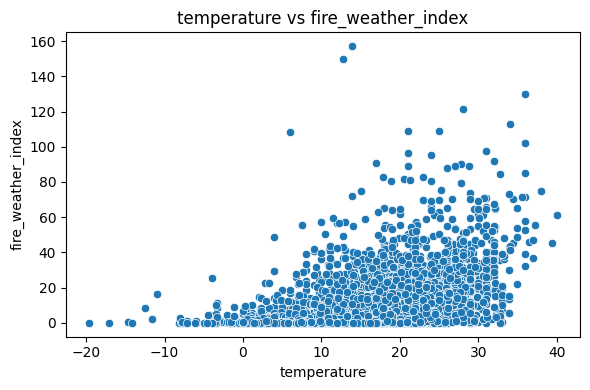

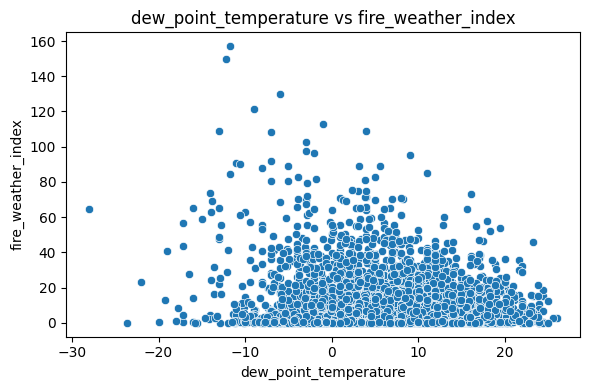

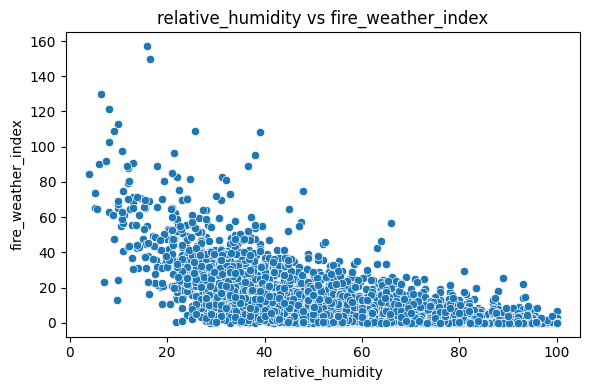

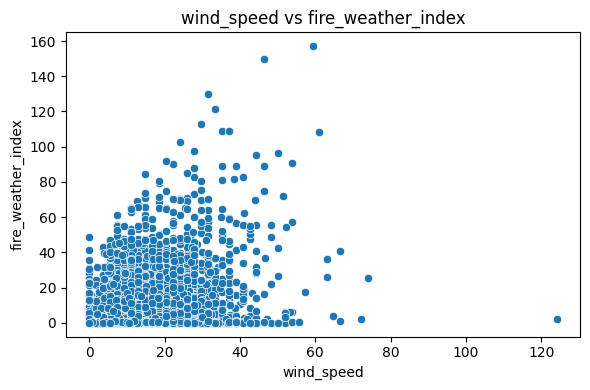

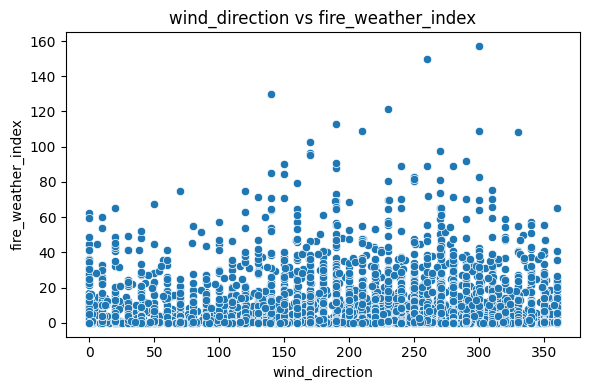

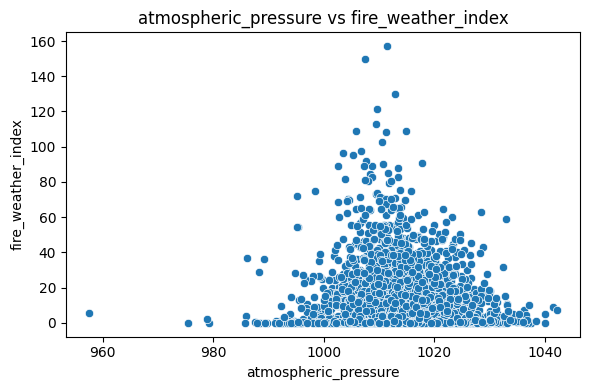

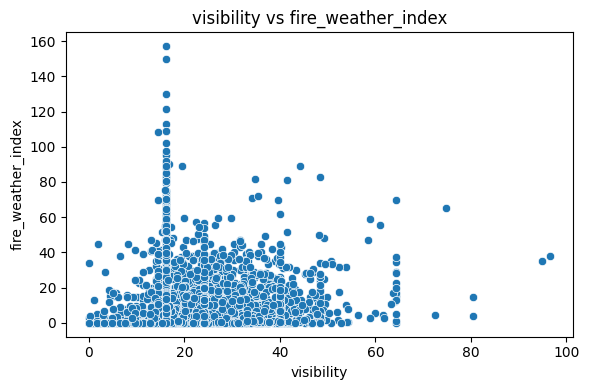

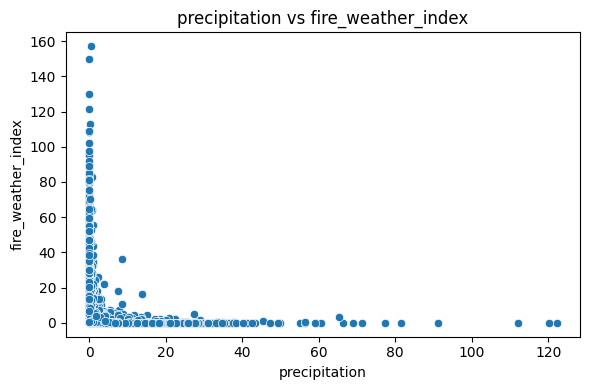

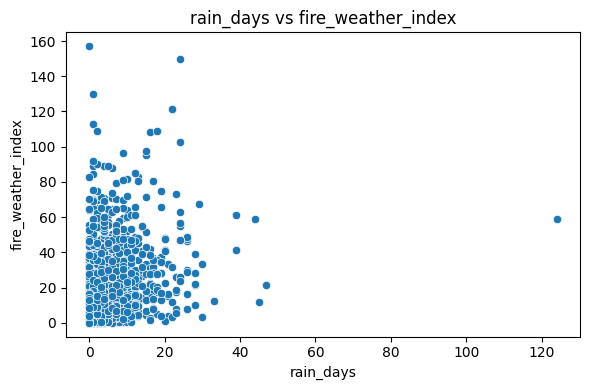

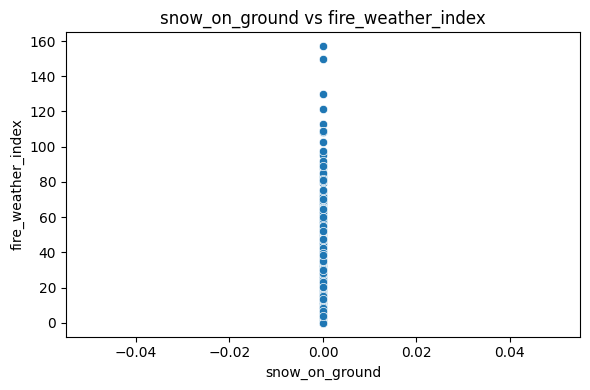

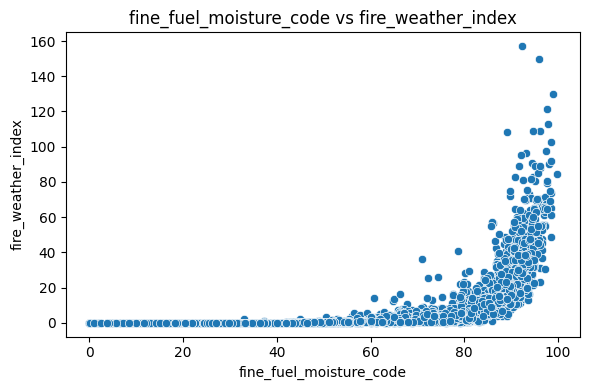

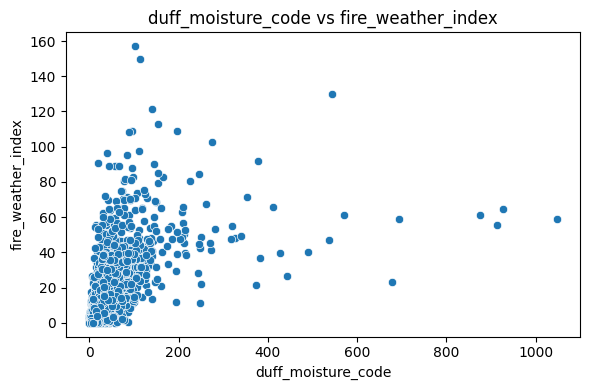

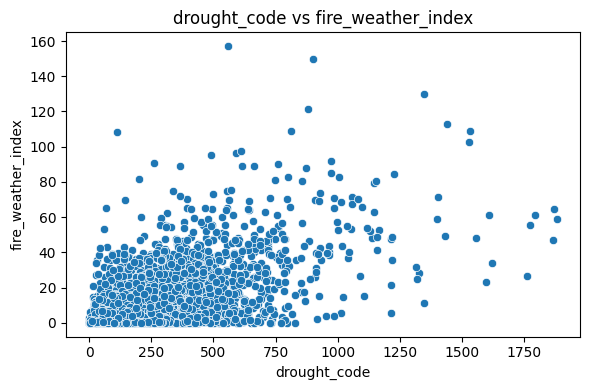

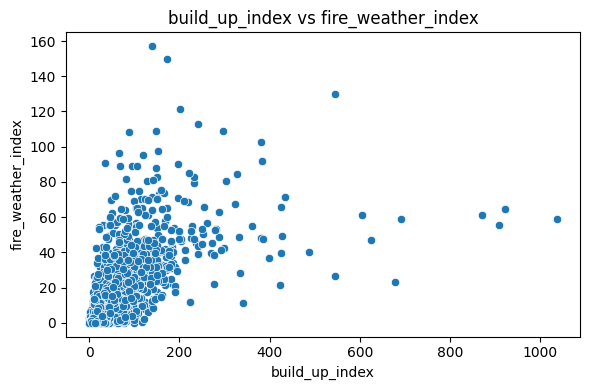

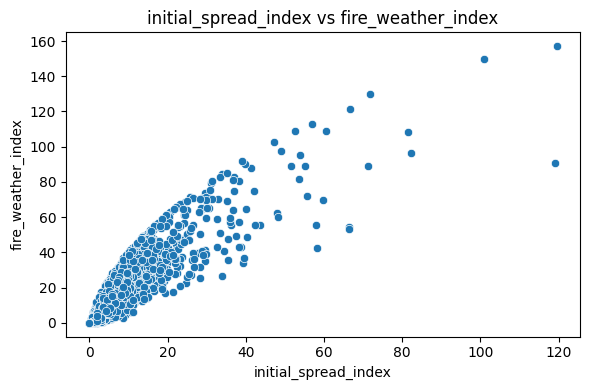

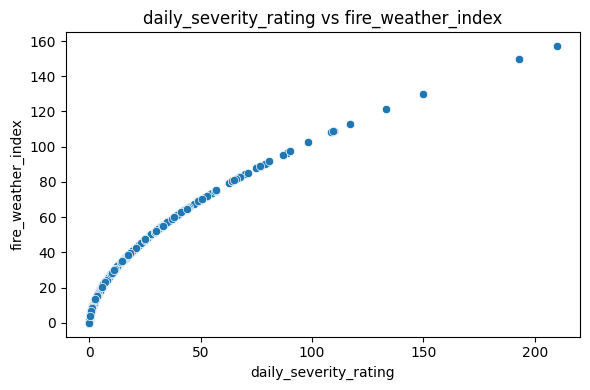

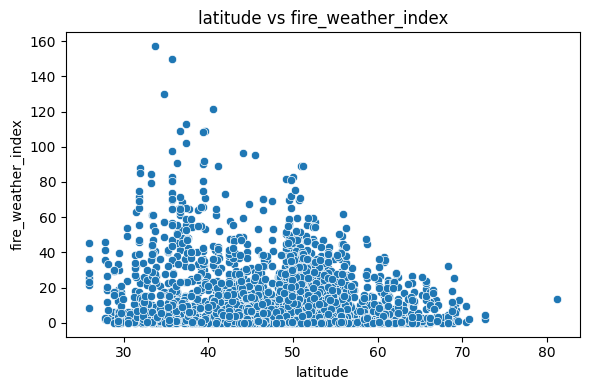

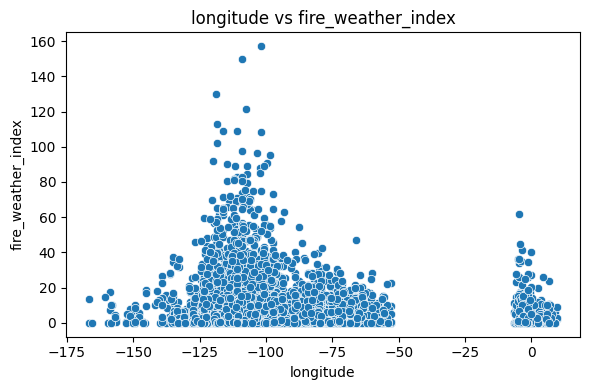

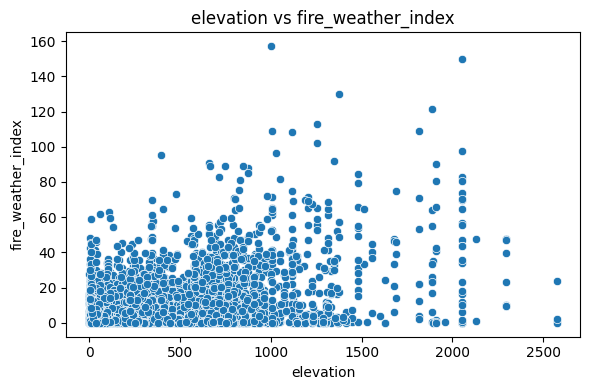

In [18]:
target = 'fire_weather_index'

numeric_data = df_sample.select_dtypes(include=['number'])
correlations = numeric_data.corr()[target].sort_values(ascending=False)
print("Correlations with target variable:\n", correlations)

# Scatter plots for each feature vs. target variable
features = [col for col in df_sample.columns if col != target and df_sample[col].dtype != 'object']

for feature in features:
    plt.figure(figsize=(6, 4))
    sns.scatterplot(x=df_sample[feature], y=df_sample[target])
    plt.title(f'{feature} vs {target}')
    plt.xlabel(feature)
    plt.ylabel(target)
    plt.tight_layout()
    plt.show()


Correlations with target variable:
 fire_weather_index         1.000000
daily_severity_rating      0.909886
initial_spread_index       0.892885
build_up_index             0.652184
duff_moisture_code         0.589460
drought_code               0.569352
fine_fuel_moisture_code    0.539630
temperature                0.435907
rain_days                  0.423825
elevation                  0.414850
wind_speed                 0.269946
wind_direction             0.051133
visibility                 0.037566
atmospheric_pressure      -0.078380
latitude                  -0.174072
dew_point_temperature     -0.192698
longitude                 -0.193402
precipitation             -0.227914
relative_humidity         -0.637423
snow_on_ground                  NaN
Name: fire_weather_index, dtype: float64


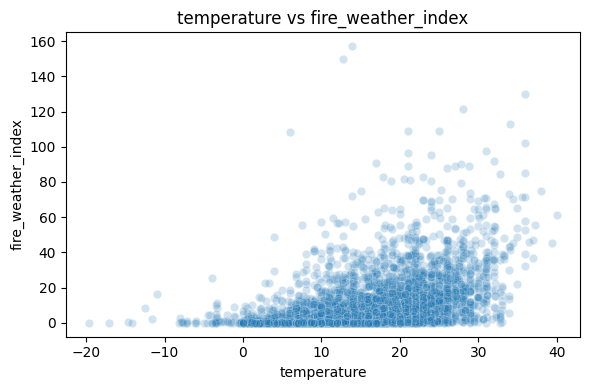

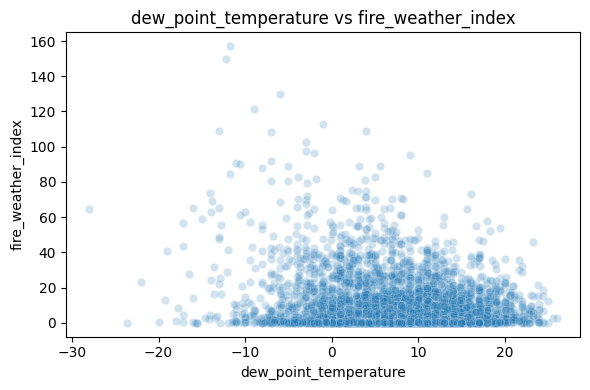

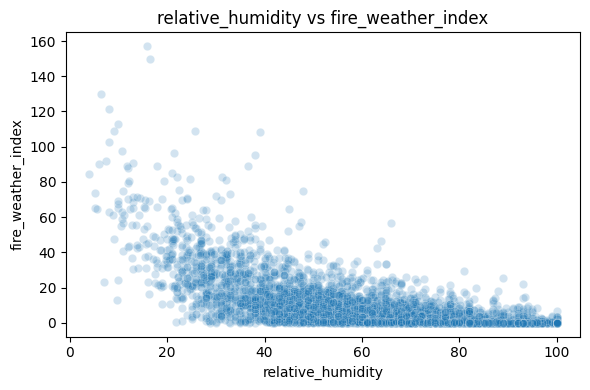

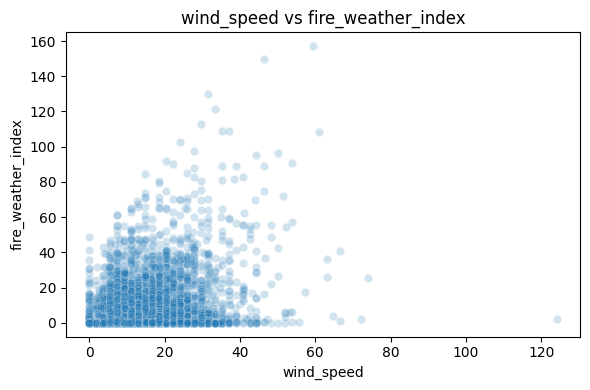

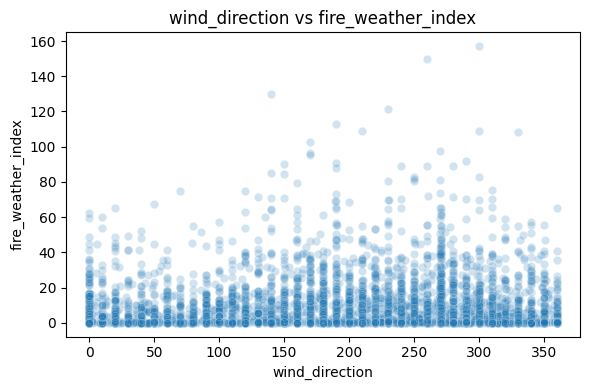

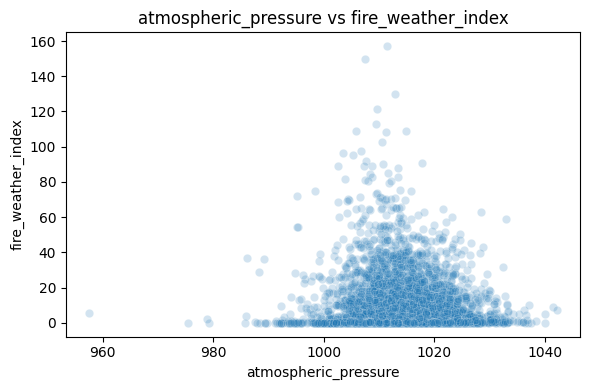

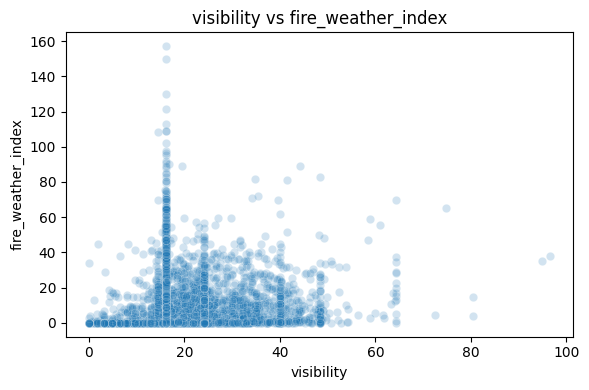

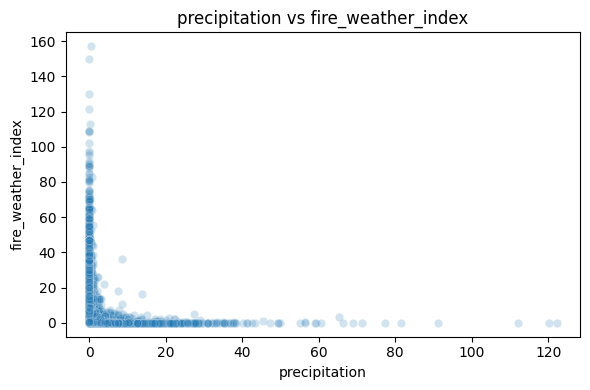

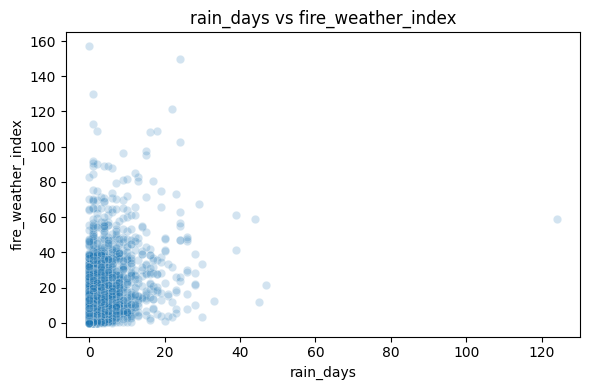

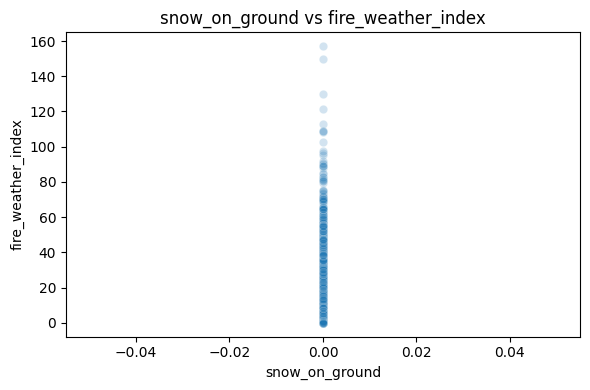

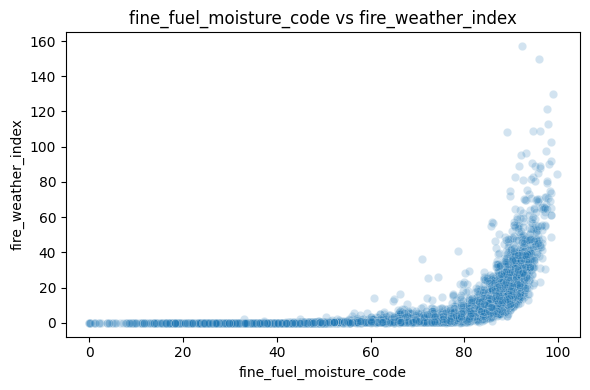

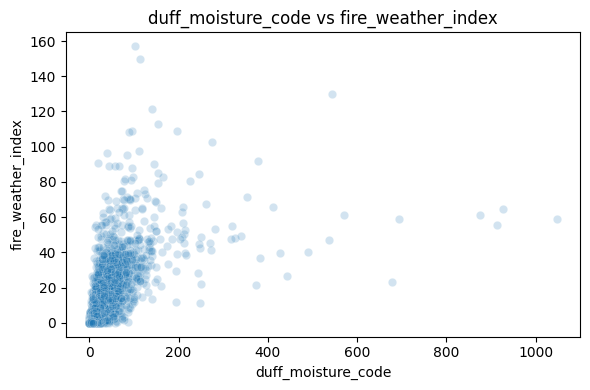

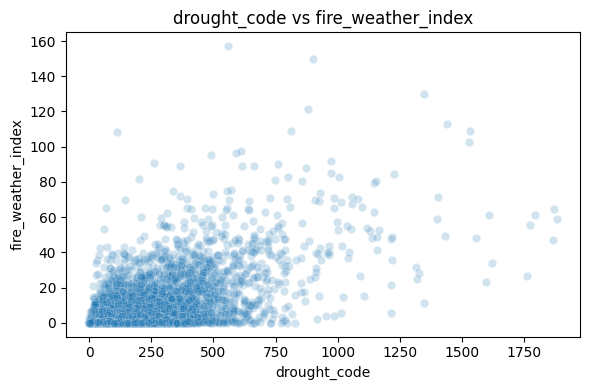

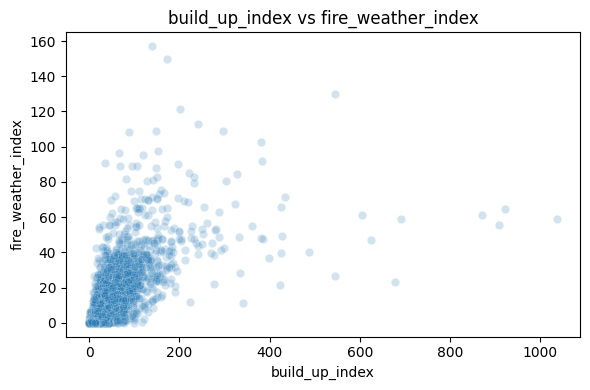

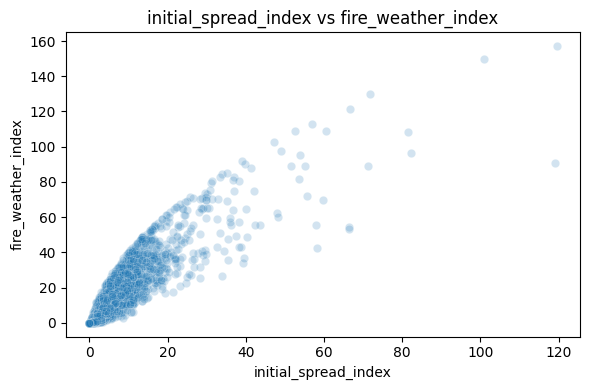

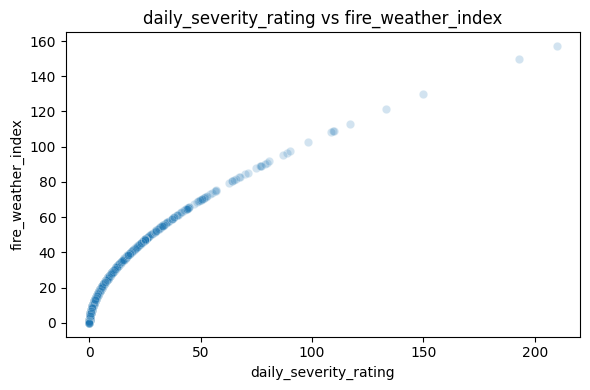

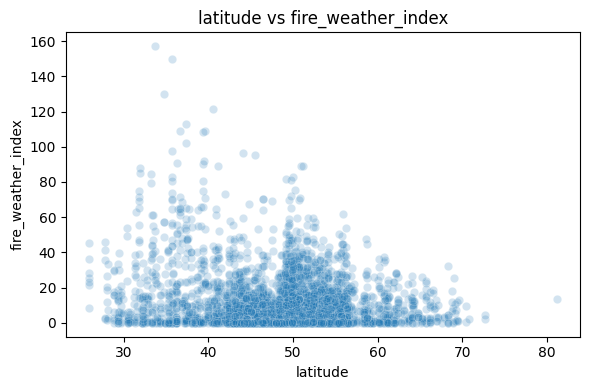

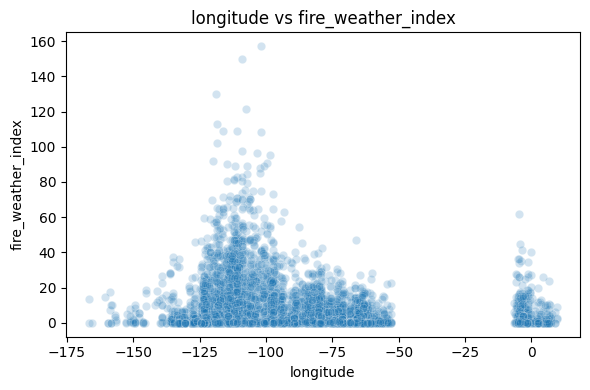

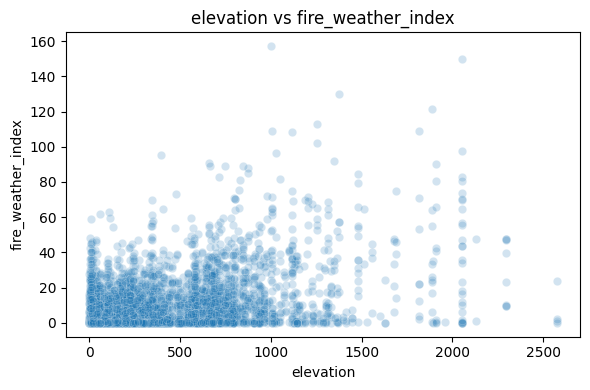

In [19]:
target = 'fire_weather_index'

numeric_data = df_sample.select_dtypes(include=['number'])
correlations = numeric_data.corr()[target].sort_values(ascending=False)
print("Correlations with target variable:\n", correlations)

# Scatter plots for each feature vs. target variable
features = [col for col in df_sample.columns if col != target and df_sample[col].dtype != 'object']

for feature in features:
    plt.figure(figsize=(6, 4))
    sns.scatterplot(x=df_sample[feature], y=df_sample[target],alpha= 0.2)
    plt.title(f'{feature} vs {target}')
    plt.xlabel(feature)
    plt.ylabel(target)
    plt.tight_layout()
    plt.show()


Correlations with target variable:
 fire_weather_index         1.000000
daily_severity_rating      0.909886
initial_spread_index       0.892885
build_up_index             0.652184
duff_moisture_code         0.589460
drought_code               0.569352
fine_fuel_moisture_code    0.539630
temperature                0.435907
rain_days                  0.423825
elevation                  0.414850
wind_speed                 0.269946
wind_direction             0.051133
visibility                 0.037566
atmospheric_pressure      -0.078380
latitude                  -0.174072
dew_point_temperature     -0.192698
longitude                 -0.193402
precipitation             -0.227914
relative_humidity         -0.637423
snow_on_ground                  NaN
Name: fire_weather_index, dtype: float64


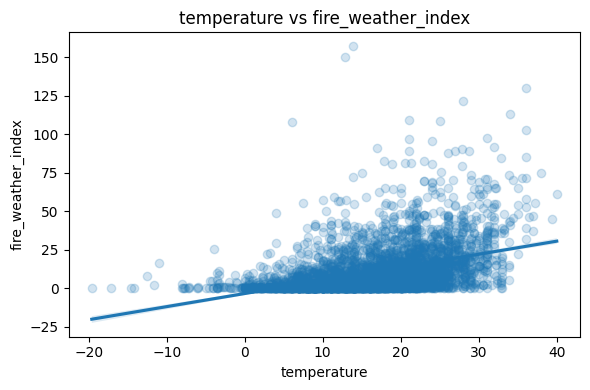

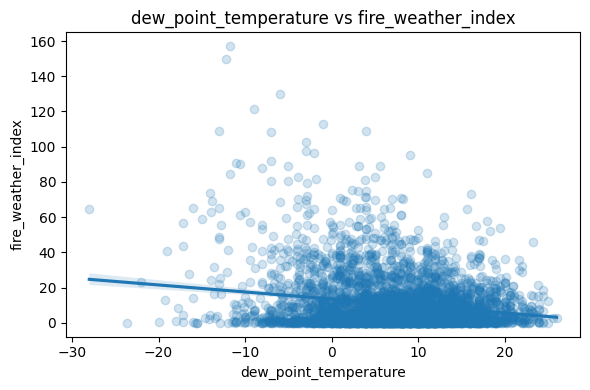

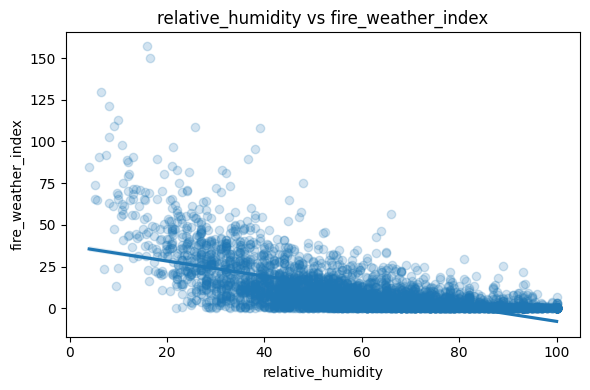

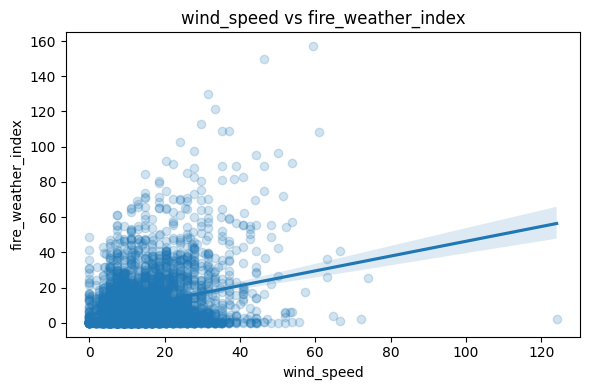

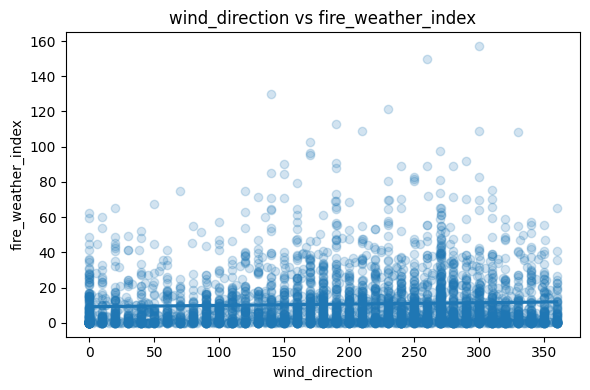

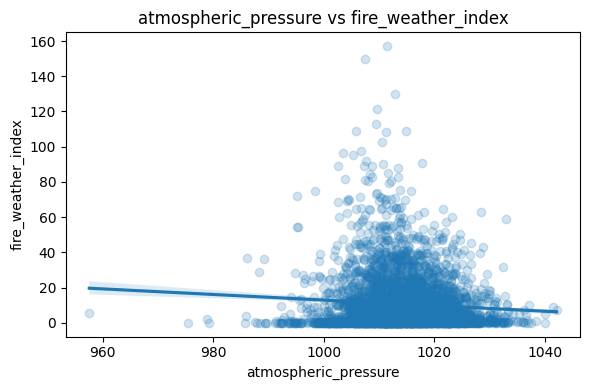

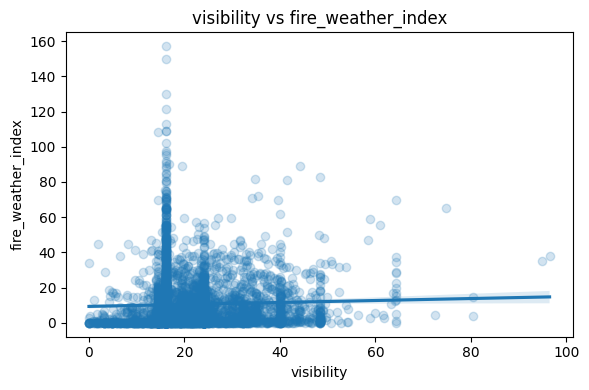

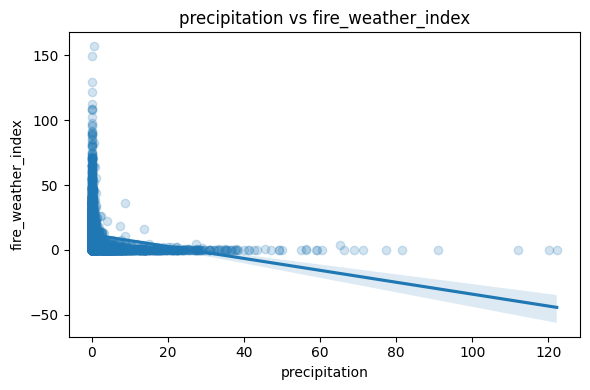

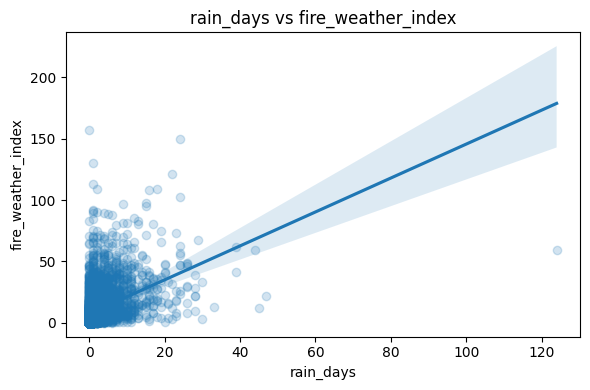

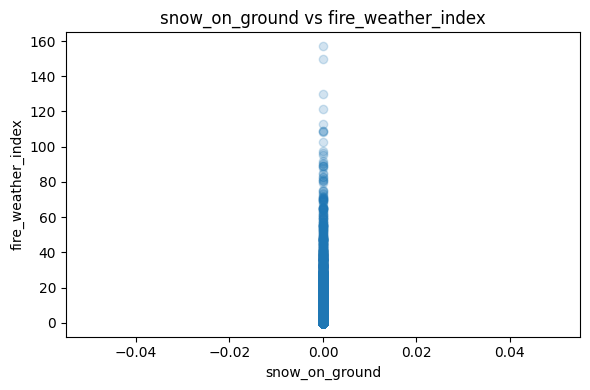

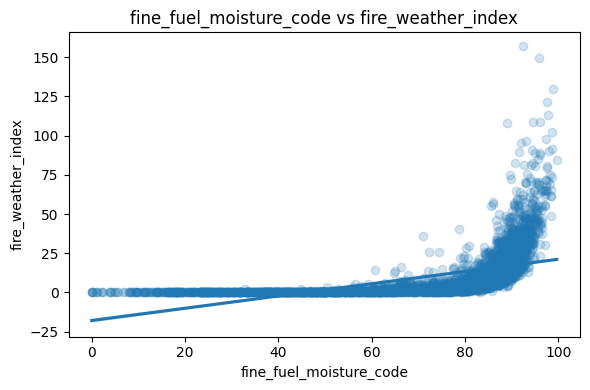

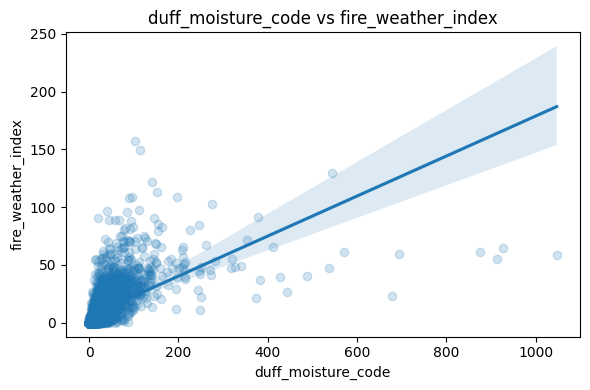

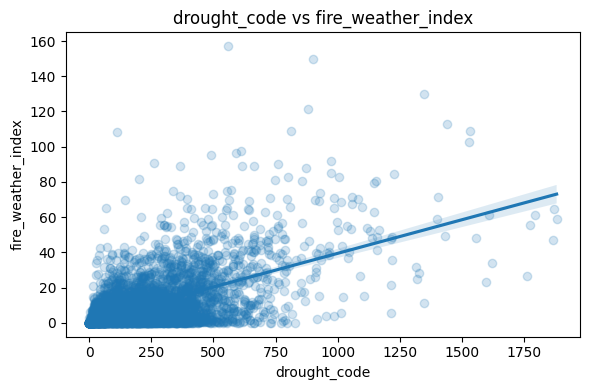

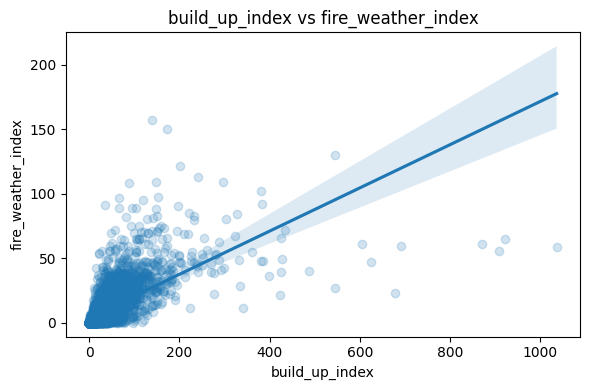

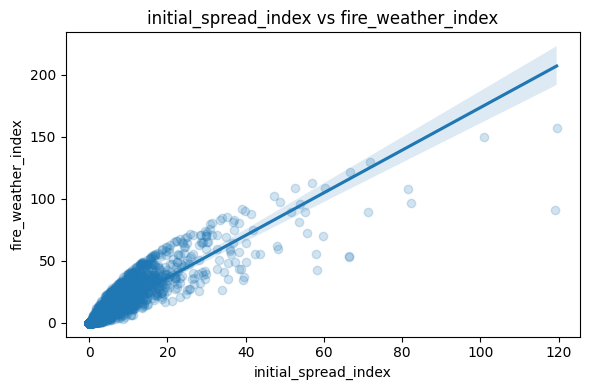

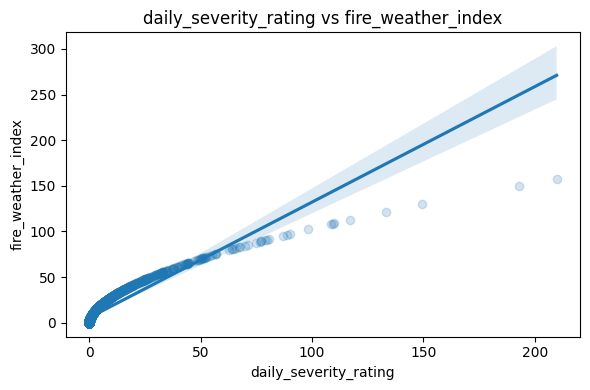

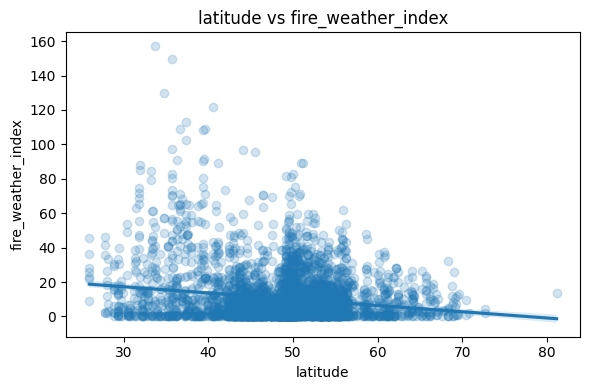

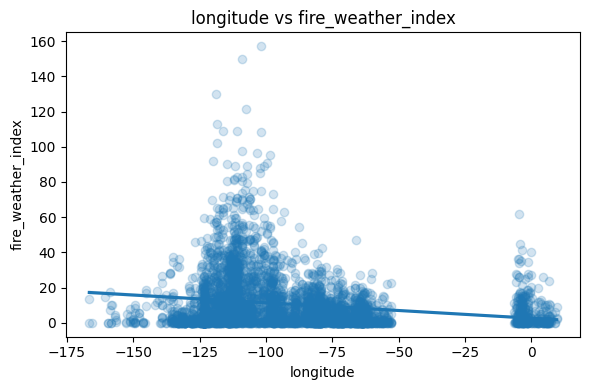

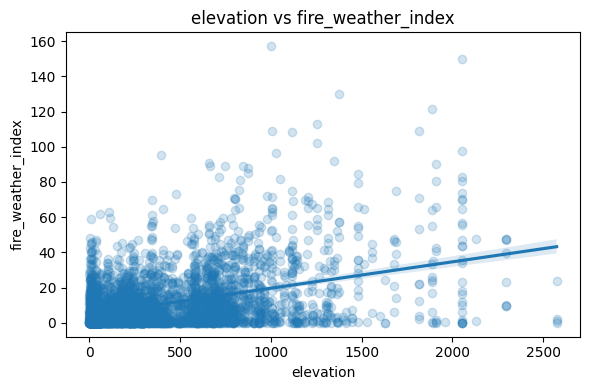

In [21]:
target = 'fire_weather_index'

numeric_data = df_sample.select_dtypes(include=['number'])
correlations = numeric_data.corr()[target].sort_values(ascending=False)
print("Correlations with target variable:\n", correlations)

# Scatter plots for each feature vs. target variable
features = [col for col in df_sample.columns if col != target and df_sample[col].dtype != 'object']

for feature in features:
    plt.figure(figsize=(6, 4))
    sns.regplot(x=df_sample[feature], y=df_sample[target], scatter_kws={'alpha':0.2})
    plt.title(f'{feature} vs {target}')
    plt.xlabel(feature)
    plt.ylabel(target)
    plt.tight_layout()
    plt.show()


In [22]:
# Select only numeric columns
num_df = df_sample.select_dtypes(include=['number'])

# Compute Pearson and Spearman correlation matrices
pearson_corr = num_df.corr(method='pearson')
spearman_corr = num_df.corr(method='spearman')



                            Pearson                                          \
                        temperature dew_point_temperature relative_humidity   
temperature                1.000000              0.624559         -0.448800   
dew_point_temperature      0.624559              1.000000          0.381485   
relative_humidity         -0.448800              0.381485          1.000000   
wind_speed                -0.114203             -0.126053          0.005855   
wind_direction            -0.004325             -0.061146         -0.083759   
atmospheric_pressure      -0.117584             -0.183021         -0.117300   
visibility                 0.023994             -0.133990         -0.246887   
precipitation             -0.113146              0.118497          0.305882   
rain_days                  0.151235             -0.110551         -0.274755   
snow_on_ground                  NaN                   NaN               NaN   
fine_fuel_moisture_code    0.469342             -0.0

In [24]:
pearson_corr

,temperature,dew_point_temperature,relative_humidity,wind_speed,wind_direction,atmospheric_pressure,visibility,precipitation,rain_days,snow_on_ground,fine_fuel_moisture_code,duff_moisture_code,drought_code,build_up_index,initial_spread_index,fire_weather_index,daily_severity_rating,latitude,longitude,elevation
temperature,1.000000,0.624559,-0.448800,-0.114203,-0.004325,-0.117584,0.023994,-0.113146,0.151235,NaN,0.469342,0.298642,0.235108,0.334161,0.325535,0.435907,0.298658,-0.268419,0.017515,0.075551
dew_point_temperature,0.624559,1.000000,0.381485,-0.126053,-0.061146,-0.183021,-0.133990,0.118497,-0.110551,NaN,-0.074447,-0.089948,-0.101379,-0.084689,-0.231887,-0.192698,-0.208824,-0.152800,0.134028,-0.288968
relative_humidity,-0.448800,0.381485,1.000000,0.005855,-0.083759,-0.117300,-0.246887,0.305882,-0.274755,NaN,-0.697892,-0.363738,-0.320205,-0.400040,-0.568373,-0.637423,-0.466661,0.110142,0.108093,-0.368038
wind_speed,-0.114203,-0.126053,0.005855,1.000000,0.151140,-0.217849,-0.054608,0.063135,-0.012824,NaN,-0.016142,-0.039770,-0.035017,-0.041487,0.416254,0.269946,0.271031,-0.049313,-0.010579,0.020766
wind_direction,-0.004325,-0.061146,-0.083759,0.151140,1.000000,-0.028542,0.036682,-0.000267,-0.007774,NaN,0.052985,0.000890,-0.001778,0.000319,0.066501,0.051133,0.044353,-0.024477,-0.085830,0.060748
atmospheric_pressure,-0.117584,-0.183021,-0.117300,-0.217849,-0.028542,1.000000,0.032650,-0.200840,0.072447,NaN,0.146232,-0.004394,-0.026018,-0.013565,-0.087062,-0.078380,-0.089424,-0.123530,-0.006227,-0.038924
visibility,0.023994,-0.133990,-0.246887,-0.054608,0.036682,0.032650,1.000000,-0.156457,0.018405,NaN,0.203344,-0.030218,0.001664,-0.021084,0.041731,0.037566,-0.007057,0.288254,0.015505,0.033499
precipitation,-0.113146,0.118497,0.305882,0.063135,-0.000267,-0.200840,-0.156457,1.000000,-0.182725,NaN,-0.588043,-0.133442,-0.180030,-0.157219,-0.208255,-0.227914,-0.123948,-0.035389,0.056604,-0.080675
rain_days,0.151235,-0.110551,-0.274755,-0.012824,-0.007774,0.072447,0.018405,-0.182725,1.000000,NaN,0.353338,0.482599,0.331462,0.484359,0.319599,0.423825,0.329381,-0.105599,-0.115224,0.115498
snow_on_ground,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


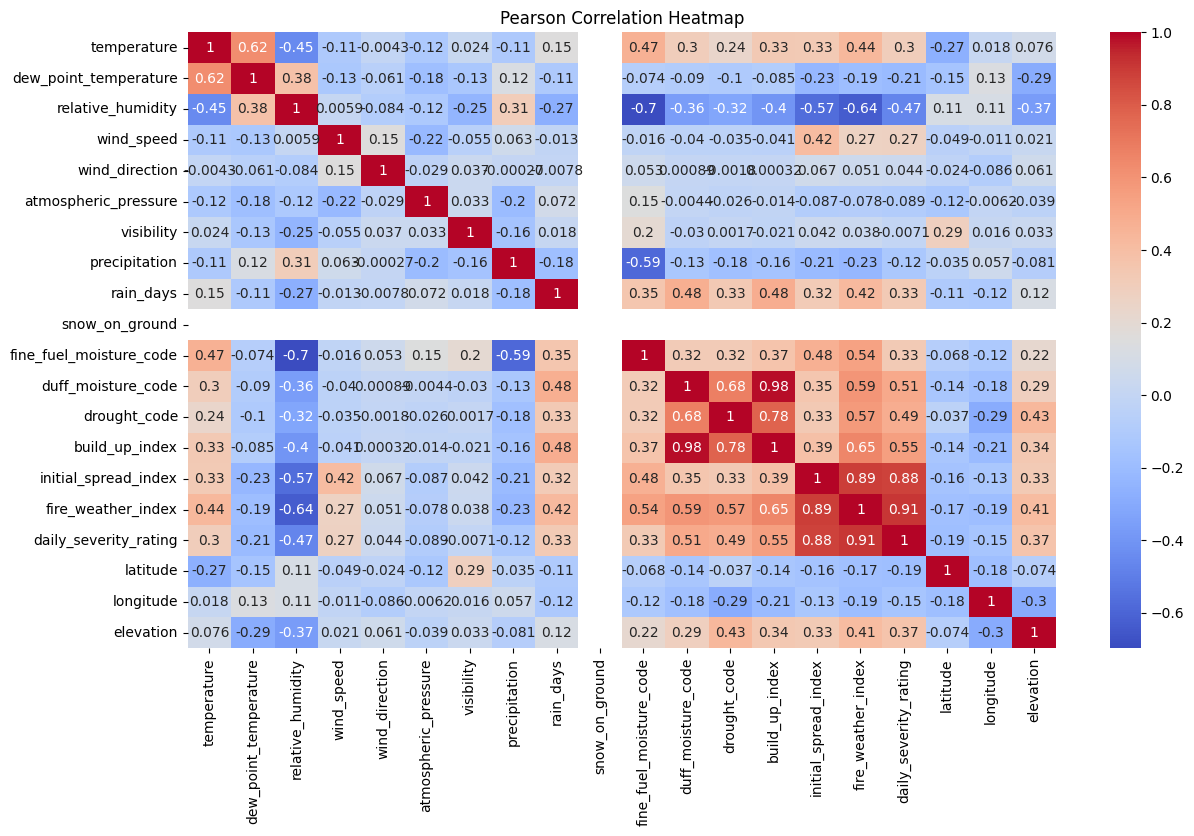

In [27]:
plt.figure(figsize=(14,8))
sns.heatmap(pearson_corr, annot=True, cmap="coolwarm")
plt.title("Pearson Correlation Heatmap")
plt.show()

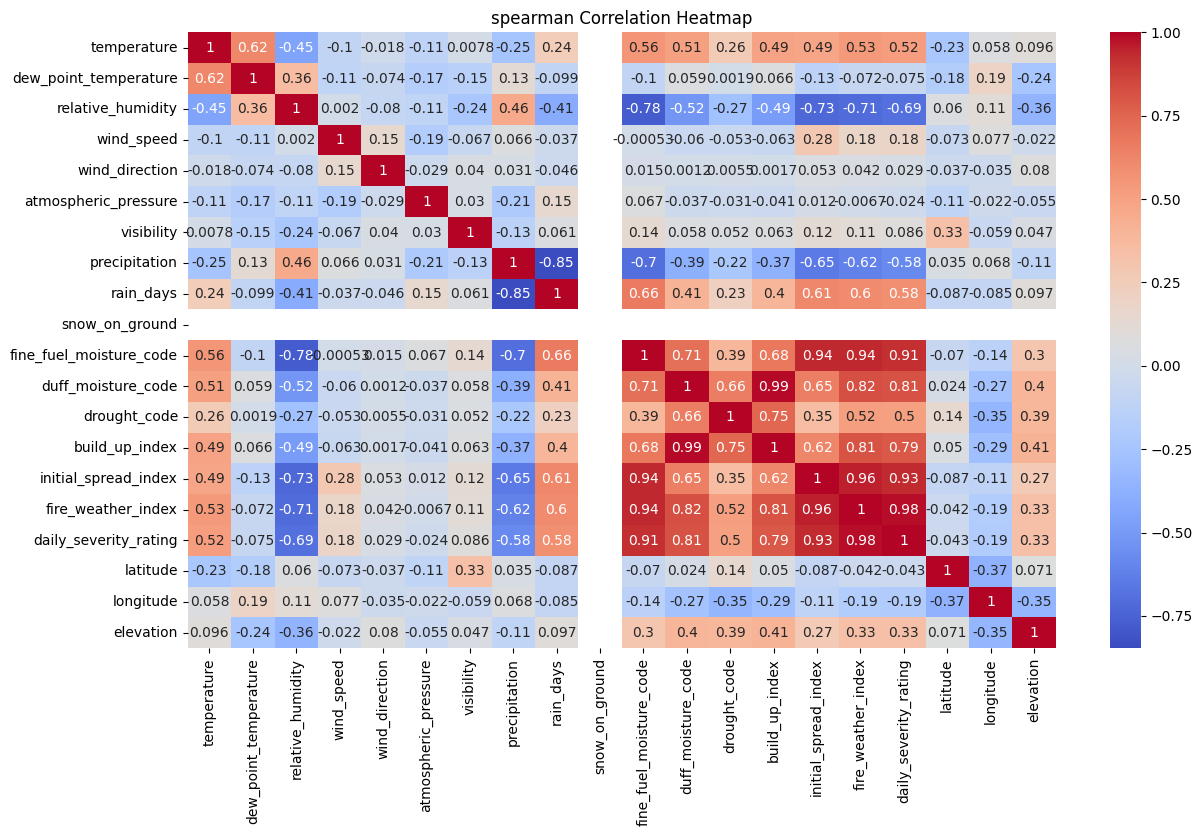

In [28]:
plt.figure(figsize=(14,8))
sns.heatmap(spearman_corr, annot=True, cmap="coolwarm")
plt.title("spearman Correlation Heatmap")
plt.show()

In [29]:
#statistical analysis

In [ ]:
Histogram / KDE plot

Q–Q plot

Shapiro-Wilk test (p > 0.05 → data looks normal)

In [ ]:
Normality of numerical data

Histogram / KDE plot

Q–Q plot

Shapiro-Wilk test (p > 0.05 → data looks normal)

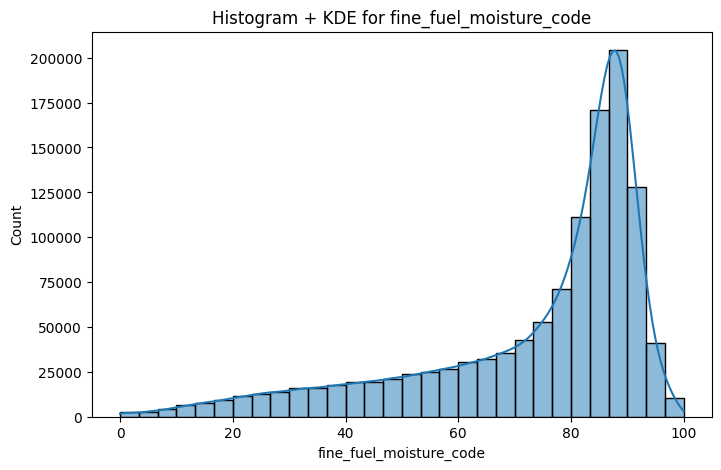

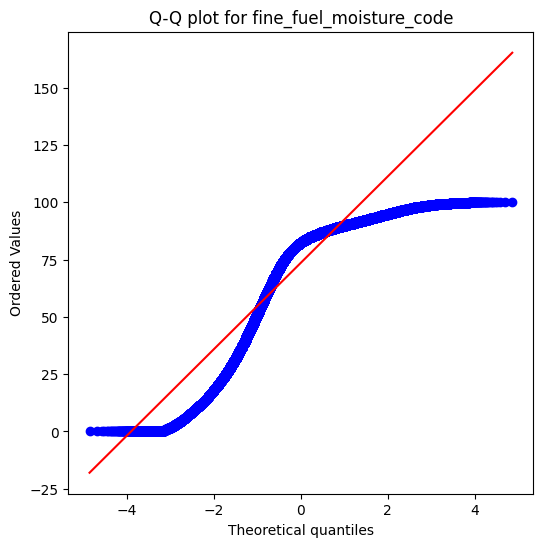

Shapiro-Wilk Test for fine_fuel_moisture_code: Statistic=0.827, p-value=0.000
Data is not normally distributed (reject H0).


C:\Users\DELL\AppData\Local\Programs\Python\Python311\Lib\site-packages\scipy\stats\_morestats.py:1882: UserWarning: p-value may not be accurate for N > 5000.
  warnings.warn("p-value may not be accurate for N > 5000.")


In [32]:
import scipy.stats as stats

col = "fine_fuel_moisture_code" 
data_col = data[col]

# 1. Histogram + KDE
plt.figure(figsize=(8,5))
sns.histplot(data_col, kde=True, bins=30)
plt.title(f"Histogram + KDE for {col}")
plt.show()

# 2. Q-Q plot
plt.figure(figsize=(6,6))
stats.probplot(data_col, dist="norm", plot=plt)
plt.title(f"Q-Q plot for {col}")
plt.show()

# 3. Shapiro-Wilk test
shapiro_stat, shapiro_p = stats.shapiro(data_col)
print(f"Shapiro-Wilk Test for {col}: Statistic={shapiro_stat:.3f}, p-value={shapiro_p:.3f}")

if shapiro_p > 0.05:
    print("Data looks normally distributed (fail to reject H0).")
else:
    print("Data is not normally distributed (reject H0).")

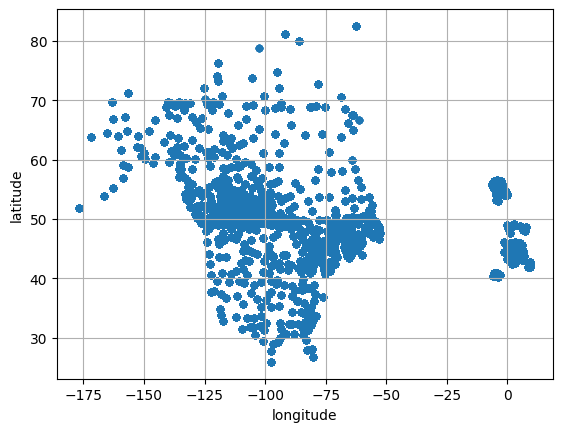

In [27]:
data.plot(kind ='scatter',y='latitude', x='longitude',grid = True)
plt.show()

In [ ]:
data.plot(kind ='scatter',y='latitude', x='longitude',grid = True, s =data['temperature'], 
          label = 'temperature', c = 'fire_weather_index', cmap = 'jet', colorbar = True,
         legend = True, figsize= (10,7))
plt.show()

C:\Users\DELL\AppData\Local\Programs\Python\Python311\Lib\site-packages\matplotlib\collections.py:996: RuntimeWarning: invalid value encountered in sqrt
  scale = np.sqrt(self._sizes) * dpi / 72.0 * self._factor
